# **Walmart sales prediction**

In [ ]:
import pandas as pd
import numpy as np
import random
import warnings
import eda
import training
import visuals
import matplotlib.pyplot as plt
import neuralforecast.models as m
import neuralforecast.auto as na
import seaborn as sns
import statsmodels.api as sm
import lightgbm as lgb
import optuna
import importlib

from eda import *
from training import *
from visuals import *
from statsmodels.tsa.stattools import adfuller
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import PoissonRegressor
from sktime.split import SlidingWindowSplitter
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive
from statsforecast.models import HoltWinters
from statsforecast.models import SklearnModel
from utilsforecast.plotting import plot_series


warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:.4f}'.format)
importlib.reload(eda)
importlib.reload(visuals)
importlib.reload(training)
%matplotlib inline

In [ ]:
import logging
logging.getLogger("cmdstanpy").disabled = True


# Pytorch
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)

# Ray 
logging.getLogger("ray").setLevel(logging.ERROR) 

# Optuna
optuna.logging.disable_default_handler()


# **1. Loading and exploration of the dataset**

**Dataset description:**

The M5 dataset consists of the following three (3) files:

File 1: “calendar.csv” Contains information about the dates the products are sold.

*	date: The date in a “y-m-d” format.
*	wm_yr_wk: The id of the week the date belongs to.
*	weekday: The type of the day (Saturday, Sunday, …, Friday).
*	wday: The id of the weekday, starting from Saturday.
*	month: The month of the date.
*	year: The year of the date.
*	event_name_1: If the date includes an event, the name of this event.
*	event_type_1: If the date includes an event, the type of this event.
*	event_name_2: If the date includes a second event, the name of this event.
*	event_type_2: If the date includes a second event, the type of this event.
*	snap_CA, snap_TX, and snap_WI: A binary variable (0 or 1) indicating whether the stores of CA,TX or WI allow SNAP2 purchases on the examined date. 1 indicates that SNAP purchases are allowed.

File 2: “sell_prices.csv” Contains information about the price of the products sold per store and date.

*	store_id: The id of the store where the product is sold.
*	item_id: The id of the product.
*	wm_yr_wk: The id of the week.
*	sell_price: The price of the product for the given week/store. The price is provided per week (average across seven days). If not available, this means that the product was not sold during the examined week. Note that although prices are constant at weekly basis, they may change through time (both training and test set).



File 3: “sales_train.csv”

Contains the historical daily unit sales data per product and store.

*	item_id: The id of the product.
*	dept_id: The id of the department the product belongs to.
*	cat_id: The id of the category the product belongs to.
*	store_id: The id of the store where the product is sold.
*	state_id: The State where the store is located.
*	d_1, d_2, …, d_i, … d_1941: The number of units sold at day i, starting from 2011-01-29.




## Combining dataframes

In [ ]:
# Loading train data to parquet file
sales = pd.read_parquet('sales_train_validation.parquet')
sales2 = pd.read_parquet('sales_train_evaluation.parquet')
prices = pd.read_parquet('sell_prices.parquet')

calendar = pd.read_csv('calendar.csv')

In [4]:
sales.head(10)

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,3,0,1,1,1,3,0,1,1
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,2,1,1,1,0,1,1,1
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,5,4,1,0,1,3,7,2
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,1,0,1,1,2,2,2,4
5,HOBBIES_1_006_CA_1_validation,HOBBIES_1_006,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,1,0,1,0,0,0,2,0,0
6,HOBBIES_1_007_CA_1_validation,HOBBIES_1_007,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,1,0,1,0,0,1,1
7,HOBBIES_1_008_CA_1_validation,HOBBIES_1_008,HOBBIES_1,HOBBIES,CA_1,CA,12,15,0,0,...,0,0,1,37,3,4,6,3,2,1
8,HOBBIES_1_009_CA_1_validation,HOBBIES_1_009,HOBBIES_1,HOBBIES,CA_1,CA,2,0,7,3,...,0,0,1,1,6,0,0,0,0,0
9,HOBBIES_1_010_CA_1_validation,HOBBIES_1_010,HOBBIES_1,HOBBIES,CA_1,CA,0,0,1,0,...,1,0,0,0,0,0,0,2,0,2


In [144]:
calendar['date'] = pd.to_datetime(calendar['date'])

In [145]:
calendar = calendar.rename(columns={'snap_CA':'CA',
                                    'snap_TX':'TX',
                                    'snap_WI':'WI'})
calendar.head(10)

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,CA,TX,WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1
5,2011-02-03,11101,Thursday,6,2,2011,d_6,NaN,NaN,NaN,NaN,1,1,1
6,2011-02-04,11101,Friday,7,2,2011,d_7,NaN,NaN,NaN,NaN,1,0,0
7,2011-02-05,11102,Saturday,1,2,2011,d_8,NaN,NaN,NaN,NaN,1,1,1
8,2011-02-06,11102,Sunday,2,2,2011,d_9,SuperBowl,Sporting,NaN,NaN,1,1,1
9,2011-02-07,11102,Monday,3,2,2011,d_10,NaN,NaN,NaN,NaN,1,1,0


In [146]:
snap = calendar.loc[:,['d','wm_yr_wk','date', 'CA','TX','WI']].melt(id_vars=['d','wm_yr_wk','date'], var_name='state_id', value_name='snap')
snap

,d,wm_yr_wk,date,state_id,snap
0,d_1,11101,2011-01-29,CA,0
1,d_2,11101,2011-01-30,CA,0
2,d_3,11101,2011-01-31,CA,0
3,d_4,11101,2011-02-01,CA,1
4,d_5,11101,2011-02-02,CA,1
...,...,...,...,...,...
5902,d_1965,11620,2016-06-15,WI,1
5903,d_1966,11620,2016-06-16,WI,0
5904,d_1967,11620,2016-06-17,WI,0
5905,d_1968,11621,2016-06-18,WI,0


In [147]:
snap['date'] = pd.to_datetime(snap['date'])

In [148]:
snap.snap = snap.snap.astype('int32')

In [8]:
prices.head(10)

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.5800
1,CA_1,HOBBIES_1_001,11326,9.5800
2,CA_1,HOBBIES_1_001,11327,8.2600
3,CA_1,HOBBIES_1_001,11328,8.2600
4,CA_1,HOBBIES_1_001,11329,8.2600
5,CA_1,HOBBIES_1_001,11330,8.2600
6,CA_1,HOBBIES_1_001,11331,8.2600
7,CA_1,HOBBIES_1_001,11332,8.2600
8,CA_1,HOBBIES_1_001,11333,8.2600
9,CA_1,HOBBIES_1_001,11334,8.2600


In [7]:
#  Conversion to long format

sales_long = sales.melt(id_vars=['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id'], var_name='d', value_name='units')
sales2_long = sales2.melt(id_vars=['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id'], var_name='d', value_name='units')

In [10]:
sales_long.head(10)

,id,item_id,dept_id,cat_id,store_id,state_id,d,units
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
5,HOBBIES_1_006_CA_1_validation,HOBBIES_1_006,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
6,HOBBIES_1_007_CA_1_validation,HOBBIES_1_007,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
7,HOBBIES_1_008_CA_1_validation,HOBBIES_1_008,HOBBIES_1,HOBBIES,CA_1,CA,d_1,12
8,HOBBIES_1_009_CA_1_validation,HOBBIES_1_009,HOBBIES_1,HOBBIES,CA_1,CA,d_1,2
9,HOBBIES_1_010_CA_1_validation,HOBBIES_1_010,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0


In [11]:
sales_long.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58327370 entries, 0 to 58327369
Data columns (total 8 columns):
 #   Column    Dtype 
---  ------    ----- 
 0   id        object
 1   item_id   object
 2   dept_id   object
 3   cat_id    object
 4   store_id  object
 5   state_id  object
 6   d         object
 7   units     int64 
dtypes: int64(1), object(7)
memory usage: 3.5+ GB


In [12]:
sales_long.isna().sum()

id          0
item_id     0
dept_id     0
cat_id      0
store_id    0
state_id    0
d           0
units       0
dtype: int64

In [13]:
sales_long.describe(include='all')

,id,item_id,dept_id,cat_id,store_id,state_id,d,units
count,58327370,58327370,58327370,58327370,58327370,58327370,58327370,58327370.0000
unique,30490,3049,7,3,10,3,1913,NaN
top,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,FOODS_3,FOODS,CA_1,CA,d_1,NaN
freq,1913,19130,15743990,27489810,5832737,23330948,30490,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.1263
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.8731
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0000


In [14]:
sales_long.iloc[:,:-1].groupby(['state_id', 'cat_id', 'dept_id']).count()[['id']]

id
state_id cat_id    dept_id             
CA       FOODS     FOODS_1      1652832
                   FOODS_2      3045496
                   FOODS_3      6297596
         HOBBIES   HOBBIES_1    3183232
                   HOBBIES_2    1140148
         HOUSEHOLD HOUSEHOLD_1  4070864
                   HOUSEHOLD_2  3940780
TX       FOODS     FOODS_1      1239624
                   FOODS_2      2284122
                   FOODS_3      4723197
         HOBBIES   HOBBIES_1    2387424
                   HOBBIES_2     855111
         HOUSEHOLD HOUSEHOLD_1  3053148
                   HOUSEHOLD_2  2955585
WI       FOODS     FOODS_1      1239624
                   FOODS_2      2284122
                   FOODS_3      4723197
         HOBBIES   HOBBIES_1    2387424
                   HOBBIES_2     855111
         HOUSEHOLD HOUSEHOLD_1  3053148
                   HOUSEHOLD_2  2955585

In [15]:
sales_long['store_id'].unique()

array(['CA_1', 'CA_2', 'CA_3', 'CA_4', 'TX_1', 'TX_2', 'TX_3', 'WI_1',
       'WI_2', 'WI_3'], dtype=object)

In [16]:
calendar.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1969 entries, 0 to 1968
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   date          1969 non-null   object
 1   wm_yr_wk      1969 non-null   int64 
 2   weekday       1969 non-null   object
 3   wday          1969 non-null   int64 
 4   month         1969 non-null   int64 
 5   year          1969 non-null   int64 
 6   d             1969 non-null   object
 7   event_name_1  162 non-null    object
 8   event_type_1  162 non-null    object
 9   event_name_2  5 non-null      object
 10  event_type_2  5 non-null      object
 11  CA            1969 non-null   int64 
 12  TX            1969 non-null   int64 
 13  WI            1969 non-null   int64 
dtypes: int64(7), object(7)
memory usage: 215.5+ KB


In [17]:
calendar.loc[~calendar.event_type_2.isna()]

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,CA,TX,WI
85,2011-04-24,11113,Sunday,2,4,2011,d_86,OrthodoxEaster,Religious,Easter,Cultural,0,0,0
827,2013-05-05,11315,Sunday,2,5,2013,d_828,OrthodoxEaster,Religious,Cinco De Mayo,Cultural,1,1,1
1177,2014-04-20,11412,Sunday,2,4,2014,d_1178,Easter,Cultural,OrthodoxEaster,Religious,0,0,0
1233,2014-06-15,11420,Sunday,2,6,2014,d_1234,NBAFinalsEnd,Sporting,Father's day,Cultural,0,1,1
1968,2016-06-19,11621,Sunday,2,6,2016,d_1969,NBAFinalsEnd,Sporting,Father's day,Cultural,0,0,0


New column 'events' will be created to capture count of events occuring on particular day.

In [155]:
# Handling multiple events

calendar.loc[(~calendar.event_type_2.isna())&(calendar.event_type_1=='Cultural'),'event_type_1'] = 'Religious'
calendar.loc[(~calendar.event_type_2.isna())&(calendar.event_name_2=='Easter'),'event_type_2'] = 'Religious'

# Event count column
calendar['events'] = calendar[['event_name_1','event_name_2']].count(axis = 1)

# Event type column encoding:
calendar['event_type'] = calendar['event_type_1']
calendar.loc[calendar.events>1,'event_type'] = 'Mixed'
calendar.loc[calendar.event_name_1.isna(),'event_type'] = 'No event'
calendar.events = calendar.events.astype('int16')

In [10]:
# Creating final dataframe with prices and calendar

df = pd.merge(sales_long, pd.concat([calendar.iloc[:,:7], calendar.iloc[:,-2:]], axis = 1), on='d', how = 'left')
df = pd.merge(df, snap.loc[:,['d','state_id','snap']], on=['d','state_id'], how = 'left')
df = pd.merge(df, prices, on=['item_id','store_id','wm_yr_wk'], how = 'left')

df_eval = pd.merge(sales2_long, pd.concat([calendar.iloc[:,:7], calendar.iloc[:,-2:]], axis = 1), on='d', how = 'left')
df_eval = pd.merge(df_eval, snap.loc[:,['d','state_id','snap']], on=['d','state_id'], how = 'left')
df_eval = pd.merge(df_eval, prices, on=['item_id','store_id','wm_yr_wk'], how = 'left')

In [21]:
df.head(10)

,id,item_id,dept_id,cat_id,store_id,state_id,d,units,date,wm_yr_wk,weekday,wday,month,year,events,event_type,snap,sell_price
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,0,No event,0,NaN
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,0,No event,0,NaN
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,0,No event,0,NaN
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,0,No event,0,NaN
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,0,No event,0,NaN
5,HOBBIES_1_006_CA_1_validation,HOBBIES_1_006,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,0,No event,0,NaN
6,HOBBIES_1_007_CA_1_validation,HOBBIES_1_007,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,0,No event,0,NaN
7,HOBBIES_1_008_CA_1_validation,HOBBIES_1_008,HOBBIES_1,HOBBIES,CA_1,CA,d_1,12,2011-01-29,11101,Saturday,1,1,2011,0,No event,0,0.4600
8,HOBBIES_1_009_CA_1_validation,HOBBIES_1_009,HOBBIES_1,HOBBIES,CA_1,CA,d_1,2,2011-01-29,11101,Saturday,1,1,2011,0,No event,0,1.5600
9,HOBBIES_1_010_CA_1_validation,HOBBIES_1_010,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,0,No event,0,3.1700


In [22]:
df_eval.tail(10)

,id,item_id,dept_id,cat_id,store_id,state_id,d,units,date,wm_yr_wk,weekday,wday,month,year,events,event_type,snap,sell_price
59181080,FOODS_3_818_WI_3_evaluation,FOODS_3_818,FOODS_3,FOODS,WI_3,WI,d_1941,0,2016-05-22,11617,Sunday,2,5,2016,0,No event,0,2.9800
59181081,FOODS_3_819_WI_3_evaluation,FOODS_3_819,FOODS_3,FOODS,WI_3,WI,d_1941,1,2016-05-22,11617,Sunday,2,5,2016,0,No event,0,1.9800
59181082,FOODS_3_820_WI_3_evaluation,FOODS_3_820,FOODS_3,FOODS,WI_3,WI,d_1941,1,2016-05-22,11617,Sunday,2,5,2016,0,No event,0,1.9800
59181083,FOODS_3_821_WI_3_evaluation,FOODS_3_821,FOODS_3,FOODS,WI_3,WI,d_1941,4,2016-05-22,11617,Sunday,2,5,2016,0,No event,0,4.9800
59181084,FOODS_3_822_WI_3_evaluation,FOODS_3_822,FOODS_3,FOODS,WI_3,WI,d_1941,4,2016-05-22,11617,Sunday,2,5,2016,0,No event,0,3.9800
59181085,FOODS_3_823_WI_3_evaluation,FOODS_3_823,FOODS_3,FOODS,WI_3,WI,d_1941,1,2016-05-22,11617,Sunday,2,5,2016,0,No event,0,2.9800
59181086,FOODS_3_824_WI_3_evaluation,FOODS_3_824,FOODS_3,FOODS,WI_3,WI,d_1941,0,2016-05-22,11617,Sunday,2,5,2016,0,No event,0,2.4800
59181087,FOODS_3_825_WI_3_evaluation,FOODS_3_825,FOODS_3,FOODS,WI_3,WI,d_1941,2,2016-05-22,11617,Sunday,2,5,2016,0,No event,0,3.9800
59181088,FOODS_3_826_WI_3_evaluation,FOODS_3_826,FOODS_3,FOODS,WI_3,WI,d_1941,0,2016-05-22,11617,Sunday,2,5,2016,0,No event,0,1.2800
59181089,FOODS_3_827_WI_3_evaluation,FOODS_3_827,FOODS_3,FOODS,WI_3,WI,d_1941,1,2016-05-22,11617,Sunday,2,5,2016,0,No event,0,1.0000


In [70]:
missing_1 = df.loc[:,['id','sell_price']].groupby('id').count().reset_index()
missing_1 = missing_1.loc[missing_1.sell_price<1913,:]
missing_1['#missing_weeks'] = (1913 - missing_1['sell_price'])/7

missing_1.sort_values(by='#missing_weeks', ascending=False)

,id,sell_price,#missing_weeks
12072,FOODS_3_595_CA_3_validation,72,263.0000
20218,HOUSEHOLD_1_020_WI_2_validation,72,263.0000
23061,HOUSEHOLD_1_311_CA_2_validation,72,263.0000
22732,HOUSEHOLD_1_278_CA_3_validation,72,263.0000
23807,HOUSEHOLD_1_386_WI_1_validation,72,263.0000
...,...,...,...
17883,HOBBIES_1_360_CA_4_validation,1906,1.0000
17887,HOBBIES_1_360_WI_1_validation,1906,1.0000
17888,HOBBIES_1_360_WI_2_validation,1906,1.0000
17910,HOBBIES_1_363_CA_1_validation,1906,1.0000


In [89]:
missing_per_count = missing_1.groupby('#missing_weeks').count()[['id']].sort_values(by='id', ascending=False).reset_index()

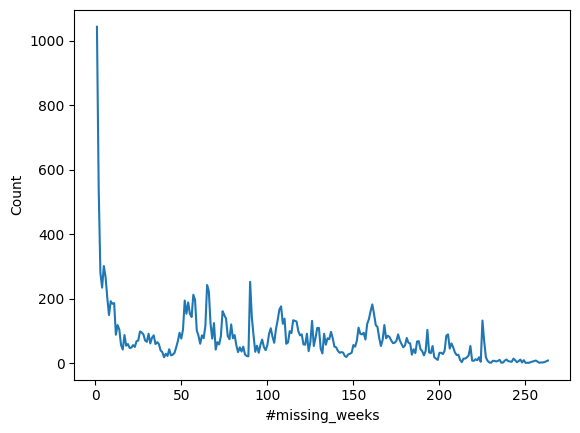

In [101]:
sns.lineplot(y = missing_per_count['id'], x = missing_per_count['#missing_weeks'])
plt.ylabel('Count')
plt.show()

In [21]:
u2 = random.choices(train.loc[train.sell_price.isna(),'id'].unique(),k=10)
u2

['FOODS_2_075_CA_2_validation',
 'FOODS_3_126_WI_3_validation',
 'FOODS_3_713_WI_1_validation',
 'FOODS_3_816_WI_2_validation',
 'FOODS_3_676_CA_3_validation',
 'HOUSEHOLD_2_165_TX_1_validation',
 'HOBBIES_1_054_WI_3_validation',
 'HOUSEHOLD_1_454_WI_2_validation',
 'FOODS_2_355_CA_1_validation',
 'HOUSEHOLD_1_534_WI_2_validation']

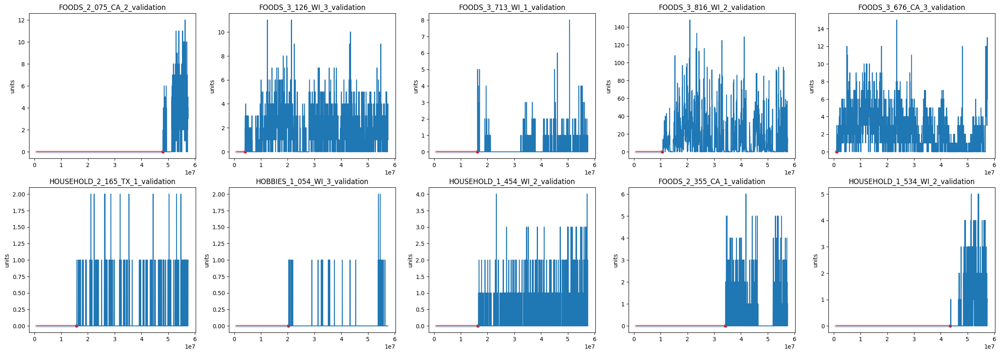

In [24]:
fig, axs = plt.subplots(2,5,figsize = (30,10))

for i, a in zip(u2, axs.ravel()):
    a.set_title(i)
    sns.lineplot(train.loc[train.id==i,'units'], ax = a)
    sns.scatterplot(train.loc[(train.id==i)&(train.sell_price.isna()),'units'], color='red', ax = a)
plt.show()

Final dataset contains series where many prices are missing, however missing prices indicate mostly that product was not sold in the store yet.

## Exploring series

In [105]:
for state in df.state_id.unique():
    display(state, df.loc[df.state_id==state].describe())

'CA'

,units,wm_yr_wk,wday,month,year,events,snap,sell_price
count,23330948.0000,23330948.0000,23330948.0000,23330948.0000,23330948.0000,23330948.0000,23330948.0000,18217798.0000
mean,1.2291,11339.1913,3.9974,6.3576,2013.2091,0.0826,0.3293,4.4139
std,4.1072,150.3742,2.0007,3.4588,1.5321,0.2828,0.4700,3.4096
min,0.0000,11101.0000,1.0000,1.0000,2011.0000,0.0000,0.0000,0.0100
25%,0.0000,11217.0000,2.0000,3.0000,2012.0000,0.0000,0.0000,2.1800
50%,0.0000,11333.0000,4.0000,6.0000,2013.0000,0.0000,0.0000,3.4700
75%,1.0000,11448.0000,6.0000,9.0000,2015.0000,0.0000,1.0000,5.7700
max,763.0000,11613.0000,7.0000,12.0000,2016.0000,2.0000,1.0000,30.9800


'TX'

,units,wm_yr_wk,wday,month,year,events,snap,sell_price
count,17498211.0000,17498211.0000,17498211.0000,17498211.0000,17498211.0000,17498211.0000,17498211.0000,14086887.0000
mean,1.0801,11339.1913,3.9974,6.3576,2013.2091,0.0826,0.3293,4.3728
std,3.8760,150.3742,2.0007,3.4588,1.5321,0.2828,0.4700,3.3699
min,0.0000,11101.0000,1.0000,1.0000,2011.0000,0.0000,0.0000,0.0200
25%,0.0000,11217.0000,2.0000,3.0000,2012.0000,0.0000,0.0000,2.0000
50%,0.0000,11333.0000,4.0000,6.0000,2013.0000,0.0000,0.0000,3.4200
75%,1.0000,11448.0000,6.0000,9.0000,2015.0000,0.0000,1.0000,5.8400
max,634.0000,11613.0000,7.0000,12.0000,2016.0000,2.0000,1.0000,52.6200


'WI'

,units,wm_yr_wk,wday,month,year,events,snap,sell_price
count,17498211.0000,17498211.0000,17498211.0000,17498211.0000,17498211.0000,17498211.0000,17498211.0000,13723272.0000
mean,1.0356,11339.1913,3.9974,6.3576,2013.2091,0.0826,0.3293,4.4366
std,3.5304,150.3742,2.0007,3.4588,1.5321,0.2828,0.4700,3.4299
min,0.0000,11101.0000,1.0000,1.0000,2011.0000,0.0000,0.0000,0.0100
25%,0.0000,11217.0000,2.0000,3.0000,2012.0000,0.0000,0.0000,2.1800
50%,0.0000,11333.0000,4.0000,6.0000,2013.0000,0.0000,0.0000,3.4700
75%,1.0000,11448.0000,6.0000,9.0000,2015.0000,0.0000,1.0000,5.9400
max,374.0000,11613.0000,7.0000,12.0000,2016.0000,2.0000,1.0000,107.3200


In [106]:
for c in df.cat_id.unique():
    display(c, df.loc[df.cat_id==c].describe())

'HOBBIES'

,units,wm_yr_wk,wday,month,year,events,snap,sell_price
count,10808450.0000,10808450.0000,10808450.0000,10808450.0000,10808450.0000,10808450.0000,10808450.0000,8642685.0000
mean,0.5667,11339.1913,3.9974,6.3576,2013.2091,0.0826,0.3293,5.3257
std,2.0366,150.3742,2.0007,3.4588,1.5321,0.2828,0.4700,4.8155
min,0.0000,11101.0000,1.0000,1.0000,2011.0000,0.0000,0.0000,0.0100
25%,0.0000,11217.0000,2.0000,3.0000,2012.0000,0.0000,0.0000,1.9700
50%,0.0000,11333.0000,4.0000,6.0000,2013.0000,0.0000,0.0000,3.9700
75%,0.0000,11448.0000,6.0000,9.0000,2015.0000,0.0000,1.0000,7.4700
max,294.0000,11613.0000,7.0000,12.0000,2016.0000,2.0000,1.0000,30.9800


'HOUSEHOLD'

,units,wm_yr_wk,wday,month,year,events,snap,sell_price
count,20029110.0000,20029110.0000,20029110.0000,20029110.0000,20029110.0000,20029110.0000,20029110.0000,15989319.0000
mean,0.7230,11339.1913,3.9974,6.3576,2013.2091,0.0826,0.3293,5.4656
std,2.0864,150.3742,2.0007,3.4588,1.5321,0.2828,0.4700,3.3719
min,0.0000,11101.0000,1.0000,1.0000,2011.0000,0.0000,0.0000,0.0100
25%,0.0000,11217.0000,2.0000,3.0000,2012.0000,0.0000,0.0000,2.9800
50%,0.0000,11333.0000,4.0000,6.0000,2013.0000,0.0000,0.0000,4.9400
75%,1.0000,11448.0000,6.0000,9.0000,2015.0000,0.0000,1.0000,6.9700
max,626.0000,11613.0000,7.0000,12.0000,2016.0000,2.0000,1.0000,107.3200


'FOODS'

,units,wm_yr_wk,wday,month,year,events,snap,sell_price
count,27489810.0000,27489810.0000,27489810.0000,27489810.0000,27489810.0000,27489810.0000,27489810.0000,21395953.0000
mean,1.6402,11339.1913,3.9974,6.3576,2013.2091,0.0826,0.3293,3.2472
std,5.1498,150.3742,2.0007,3.4588,1.5321,0.2828,0.4700,2.1295
min,0.0000,11101.0000,1.0000,1.0000,2011.0000,0.0000,0.0000,0.0100
25%,0.0000,11217.0000,2.0000,3.0000,2012.0000,0.0000,0.0000,1.9800
50%,0.0000,11333.0000,4.0000,6.0000,2013.0000,0.0000,0.0000,2.6800
75%,1.0000,11448.0000,6.0000,9.0000,2015.0000,0.0000,1.0000,3.9700
max,763.0000,11613.0000,7.0000,12.0000,2016.0000,2.0000,1.0000,19.4800


In [107]:
for dept in df.dept_id.unique():
    display(dept, df.loc[df.dept_id==dept].describe())

'HOBBIES_1'

,units,wm_yr_wk,wday,month,year,events,snap,sell_price
count,7958080.0000,7958080.0000,7958080.0000,7958080.0000,7958080.0000,7958080.0000,7958080.0000,6468599.0000
mean,0.7032,11339.1913,3.9974,6.3576,2013.2091,0.0826,0.3293,6.2111
std,2.3153,150.3742,2.0007,3.4588,1.5321,0.2828,0.4700,5.1644
min,0.0000,11101.0000,1.0000,1.0000,2011.0000,0.0000,0.0000,0.0100
25%,0.0000,11217.0000,2.0000,3.0000,2012.0000,0.0000,0.0000,2.3800
50%,0.0000,11333.0000,4.0000,6.0000,2013.0000,0.0000,0.0000,4.8800
75%,1.0000,11448.0000,6.0000,9.0000,2015.0000,0.0000,1.0000,8.9700
max,294.0000,11613.0000,7.0000,12.0000,2016.0000,2.0000,1.0000,30.9800


'HOBBIES_2'

,units,wm_yr_wk,wday,month,year,events,snap,sell_price
count,2850370.0000,2850370.0000,2850370.0000,2850370.0000,2850370.0000,2850370.0000,2850370.0000,2174086.0000
mean,0.1854,11339.1913,3.9974,6.3576,2013.2091,0.0826,0.3293,2.6914
std,0.7518,150.3742,2.0007,3.4588,1.5321,0.2828,0.4700,1.8864
min,0.0000,11101.0000,1.0000,1.0000,2011.0000,0.0000,0.0000,0.0500
25%,0.0000,11217.0000,2.0000,3.0000,2012.0000,0.0000,0.0000,0.9700
50%,0.0000,11333.0000,4.0000,6.0000,2013.0000,0.0000,0.0000,2.4700
75%,0.0000,11448.0000,6.0000,9.0000,2015.0000,0.0000,1.0000,3.8800
max,135.0000,11613.0000,7.0000,12.0000,2016.0000,2.0000,1.0000,9.9700


'HOUSEHOLD_1'

,units,wm_yr_wk,wday,month,year,events,snap,sell_price
count,10177160.0000,10177160.0000,10177160.0000,10177160.0000,10177160.0000,10177160.0000,10177160.0000,7797559.0000
mean,1.1300,11339.1913,3.9974,6.3576,2013.2091,0.0826,0.3293,5.0527
std,2.7501,150.3742,2.0007,3.4588,1.5321,0.2828,0.4700,3.6126
min,0.0000,11101.0000,1.0000,1.0000,2011.0000,0.0000,0.0000,0.0100
25%,0.0000,11217.0000,2.0000,3.0000,2012.0000,0.0000,0.0000,2.7700
50%,0.0000,11333.0000,4.0000,6.0000,2013.0000,0.0000,0.0000,3.9700
75%,1.0000,11448.0000,6.0000,9.0000,2015.0000,0.0000,1.0000,6.2400
max,626.0000,11613.0000,7.0000,12.0000,2016.0000,2.0000,1.0000,29.9700


'HOUSEHOLD_2'

,units,wm_yr_wk,wday,month,year,events,snap,sell_price
count,9851950.0000,9851950.0000,9851950.0000,9851950.0000,9851950.0000,9851950.0000,9851950.0000,8191760.0000
mean,0.3025,11339.1913,3.9974,6.3576,2013.2091,0.0826,0.3293,5.8586
std,0.8301,150.3742,2.0007,3.4588,1.5321,0.2828,0.4700,3.0745
min,0.0000,11101.0000,1.0000,1.0000,2011.0000,0.0000,0.0000,0.0500
25%,0.0000,11217.0000,2.0000,3.0000,2012.0000,0.0000,0.0000,3.9700
50%,0.0000,11333.0000,4.0000,6.0000,2013.0000,0.0000,0.0000,5.6400
75%,0.0000,11448.0000,6.0000,9.0000,2015.0000,0.0000,1.0000,6.9700
max,601.0000,11613.0000,7.0000,12.0000,2016.0000,2.0000,1.0000,107.3200


'FOODS_1'

,units,wm_yr_wk,wday,month,year,events,snap,sell_price
count,4132080.0000,4132080.0000,4132080.0000,4132080.0000,4132080.0000,4132080.0000,4132080.0000,3530738.0000
mean,1.2314,11339.1913,3.9974,6.3576,2013.2091,0.0826,0.3293,3.3732
std,3.0486,150.3742,2.0007,3.4588,1.5321,0.2828,0.4700,2.0995
min,0.0000,11101.0000,1.0000,1.0000,2011.0000,0.0000,0.0000,0.0700
25%,0.0000,11217.0000,2.0000,3.0000,2012.0000,0.0000,0.0000,1.9700
50%,0.0000,11333.0000,4.0000,6.0000,2013.0000,0.0000,0.0000,2.5400
75%,1.0000,11448.0000,6.0000,9.0000,2015.0000,0.0000,1.0000,4.7400
max,166.0000,11613.0000,7.0000,12.0000,2016.0000,2.0000,1.0000,12.9800


'FOODS_2'

,units,wm_yr_wk,wday,month,year,events,snap,sell_price
count,7613740.0000,7613740.0000,7613740.0000,7613740.0000,7613740.0000,7613740.0000,7613740.0000,5520355.0000
mean,1.0021,11339.1913,3.9974,6.3576,2013.2091,0.0826,0.3293,4.0789
std,2.6918,150.3742,2.0007,3.4588,1.5321,0.2828,0.4700,2.6031
min,0.0000,11101.0000,1.0000,1.0000,2011.0000,0.0000,0.0000,0.2000
25%,0.0000,11217.0000,2.0000,3.0000,2012.0000,0.0000,0.0000,2.4700
50%,0.0000,11333.0000,4.0000,6.0000,2013.0000,0.0000,0.0000,2.9800
75%,1.0000,11448.0000,6.0000,9.0000,2015.0000,0.0000,1.0000,5.0000
max,634.0000,11613.0000,7.0000,12.0000,2016.0000,2.0000,1.0000,13.9800


'FOODS_3'

,units,wm_yr_wk,wday,month,year,events,snap,sell_price
count,15743990.0000,15743990.0000,15743990.0000,15743990.0000,15743990.0000,15743990.0000,15743990.0000,12344860.0000
mean,2.0562,11339.1913,3.9974,6.3576,2013.2091,0.0826,0.3293,2.8392
std,6.3205,150.3742,2.0007,3.4588,1.5321,0.2828,0.4700,1.7574
min,0.0000,11101.0000,1.0000,1.0000,2011.0000,0.0000,0.0000,0.0100
25%,0.0000,11217.0000,2.0000,3.0000,2012.0000,0.0000,0.0000,1.8800
50%,0.0000,11333.0000,4.0000,6.0000,2013.0000,0.0000,0.0000,2.5000
75%,2.0000,11448.0000,6.0000,9.0000,2015.0000,0.0000,1.0000,3.5000
max,763.0000,11613.0000,7.0000,12.0000,2016.0000,2.0000,1.0000,19.4800


## Units sold, price visualization

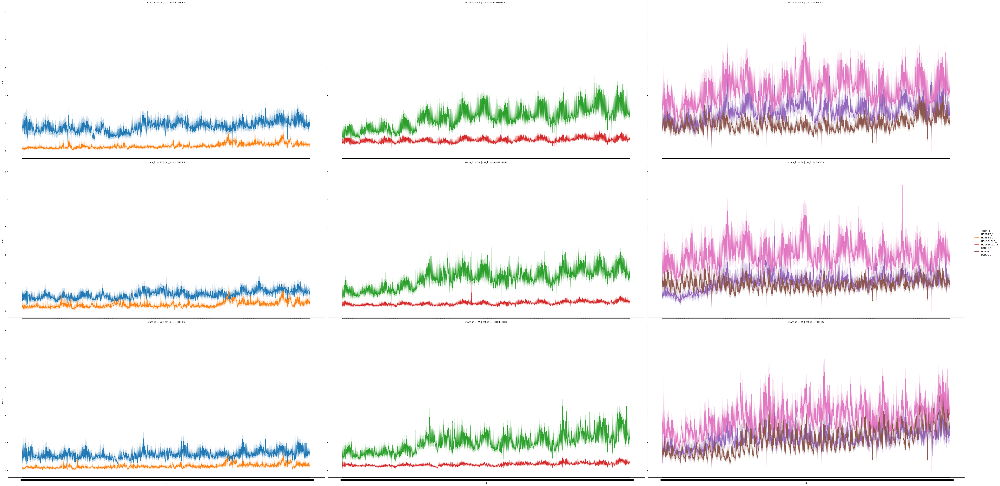

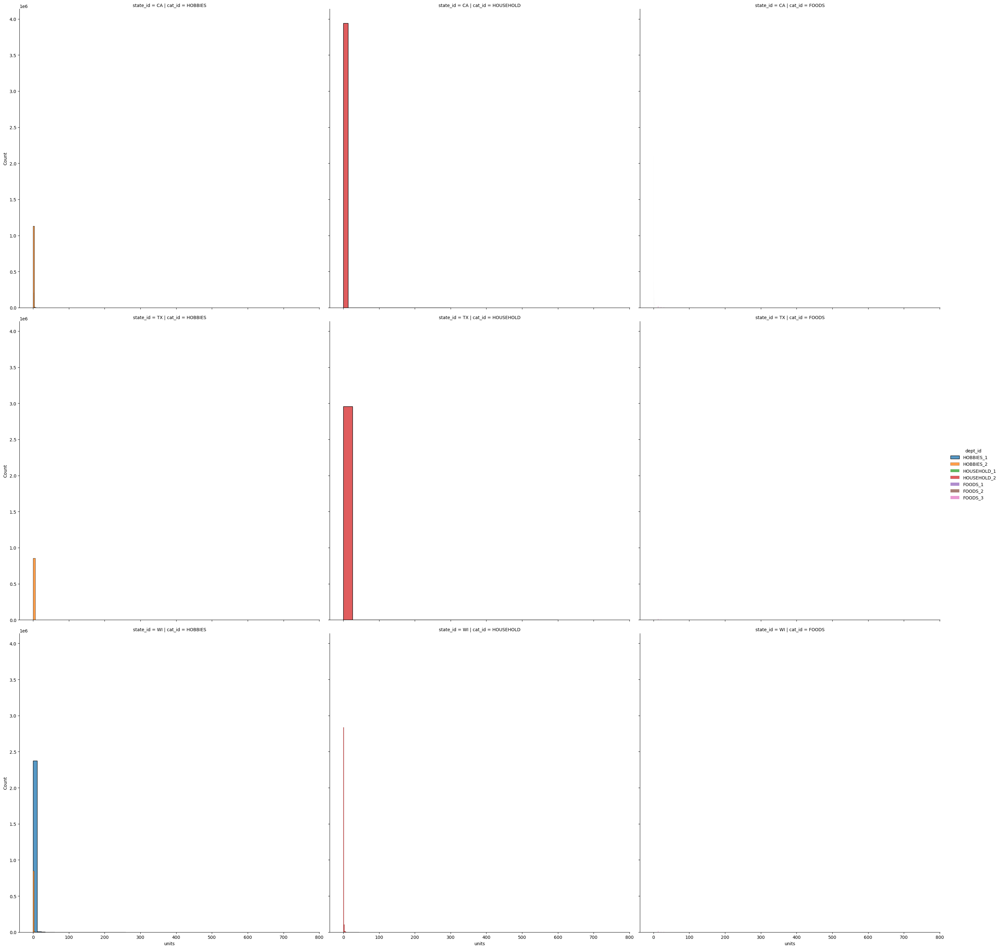

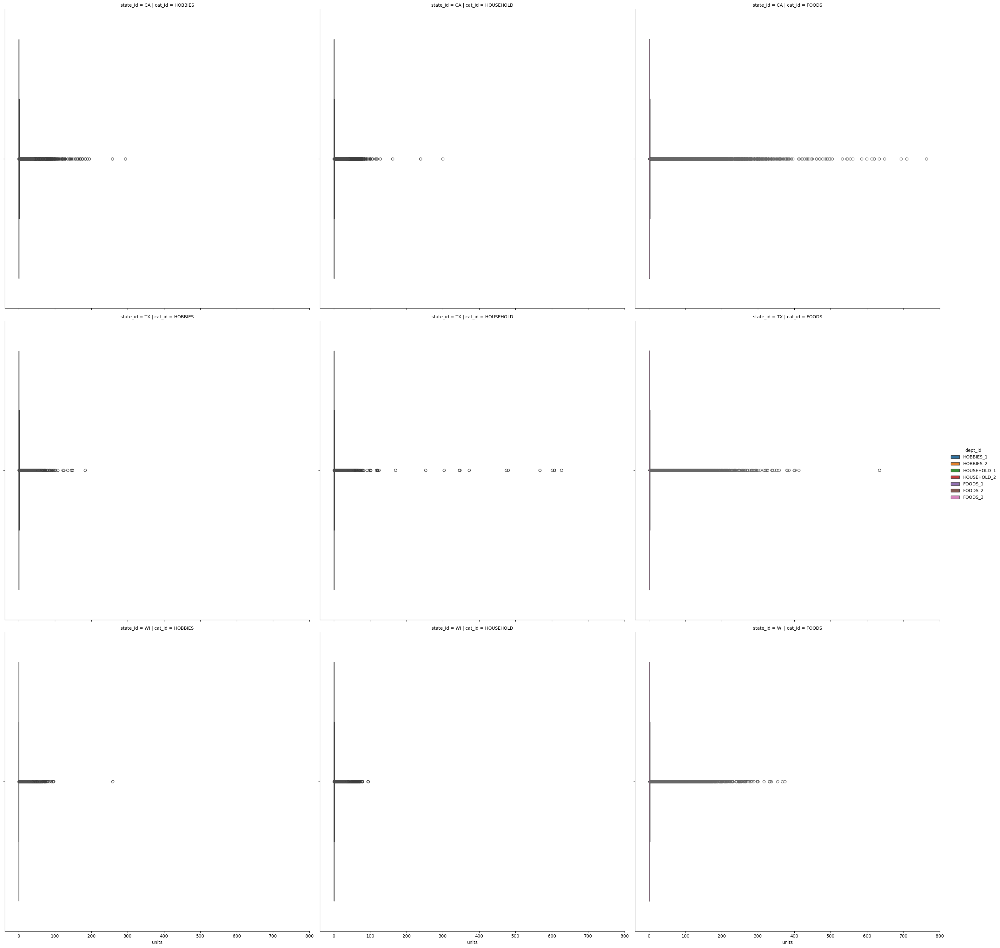

In [19]:
grid('units')

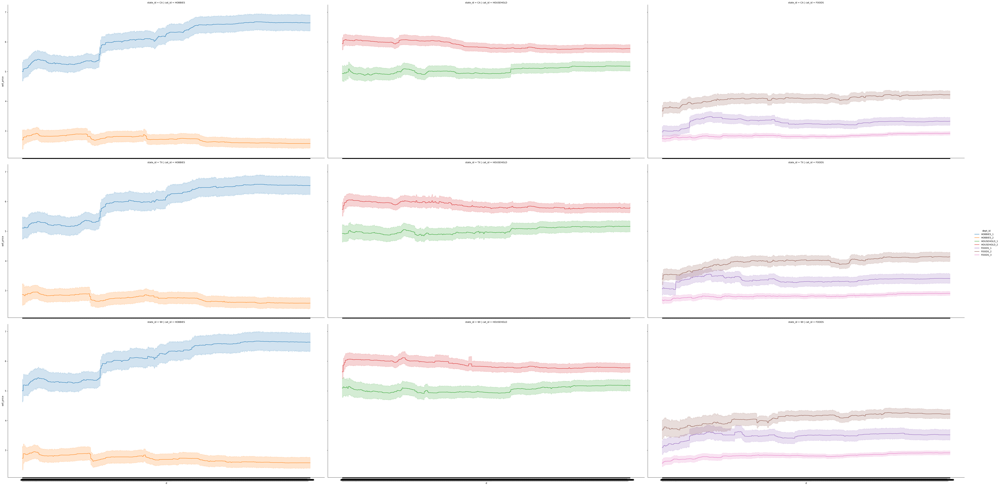

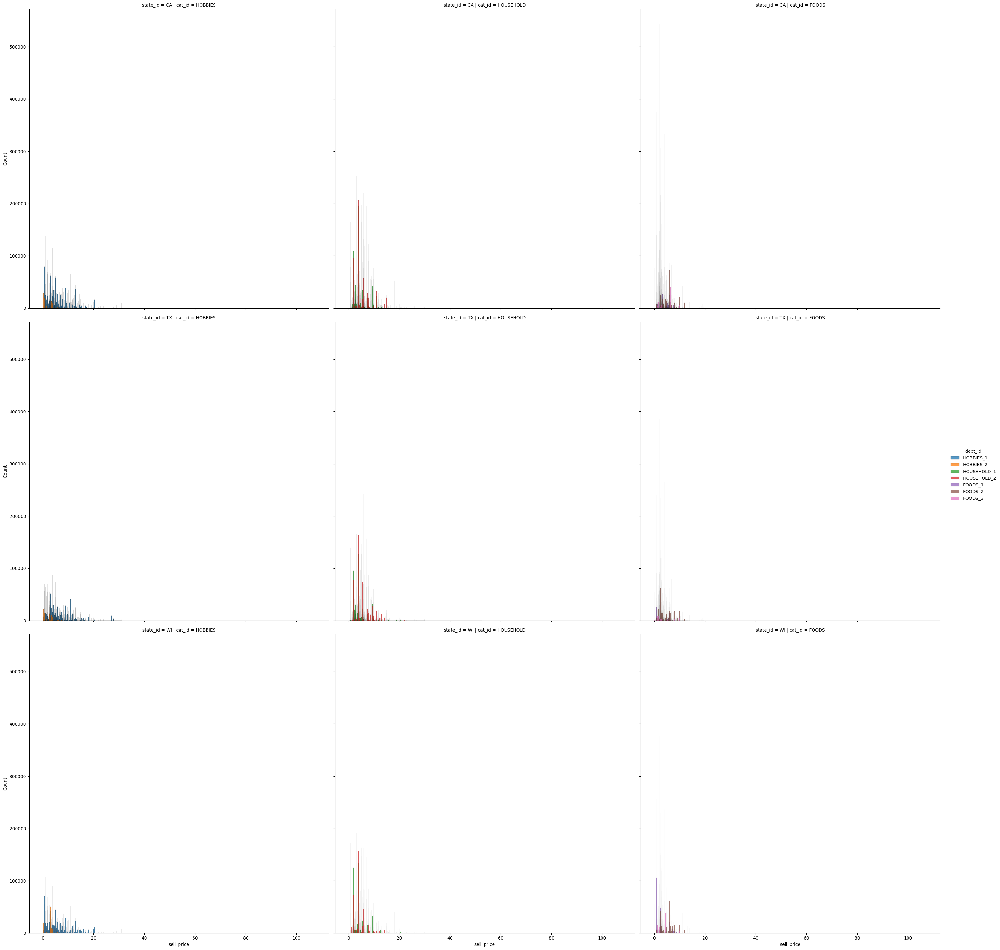

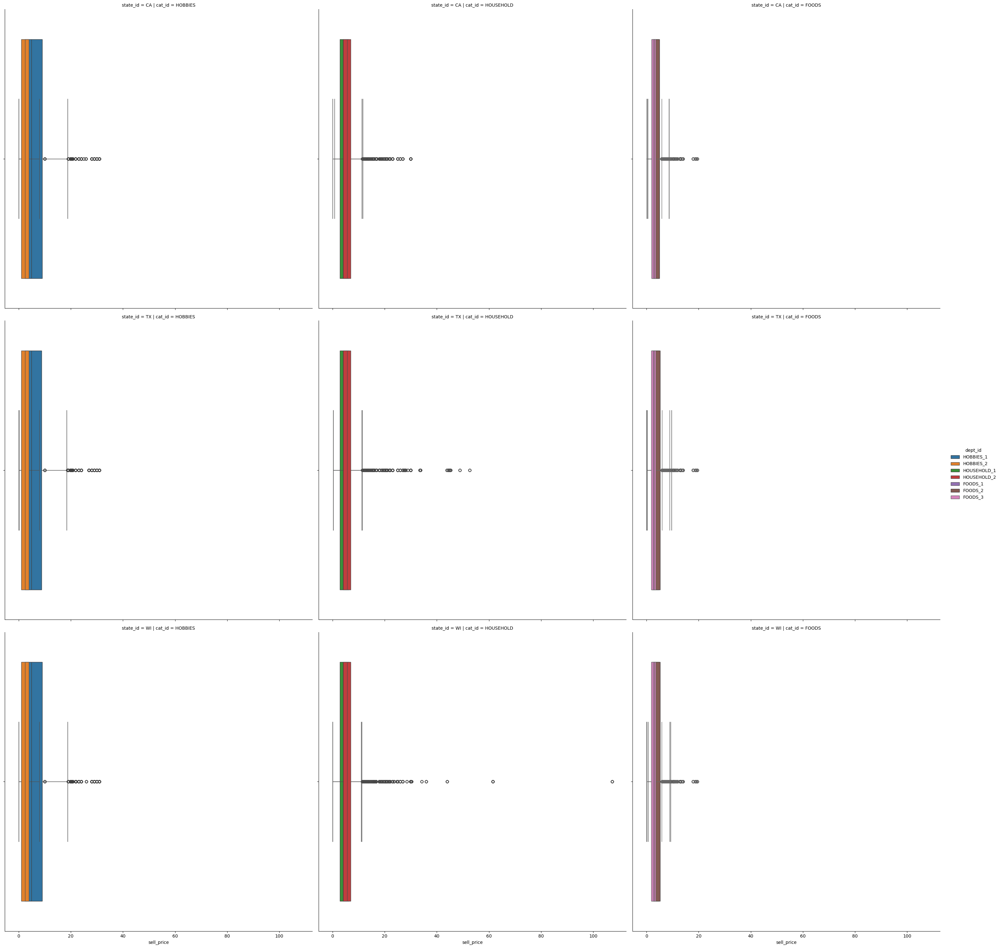

In [20]:
grid('sell_price')

*   For both units sold and sell price, data patterns do not vary much depending on state
*   Differences between each department within one category are similar for all states, except for foods
*   For foods category, in Caliornia department foods_1 has higher sales than foods_2, while those are similar in other states
*   Distributions are right-skewed for both variables

## Correlations

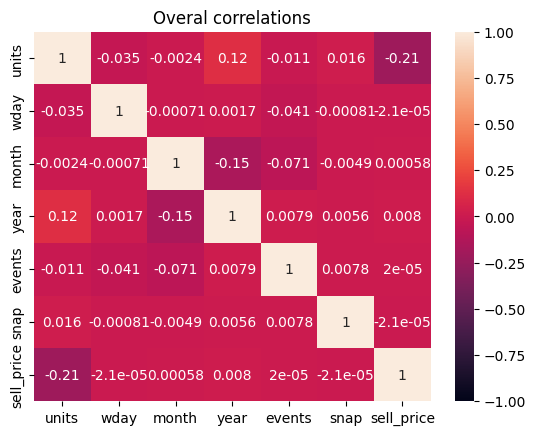

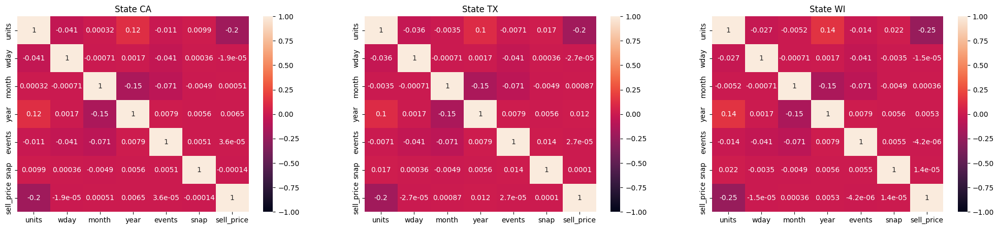

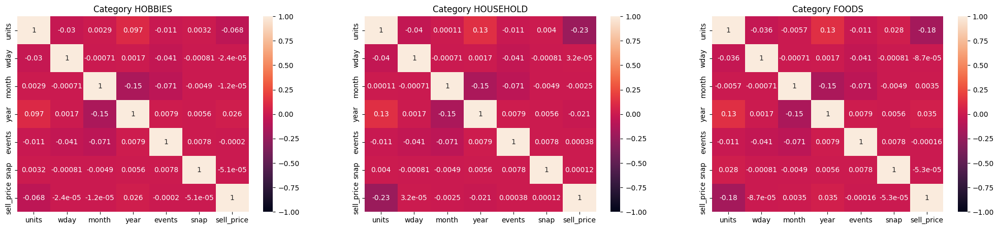

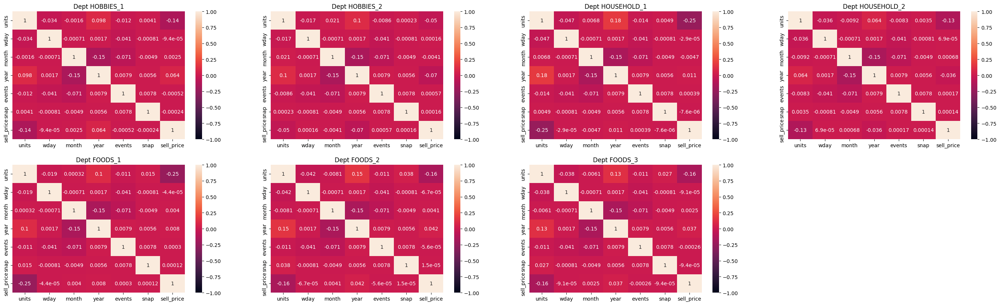

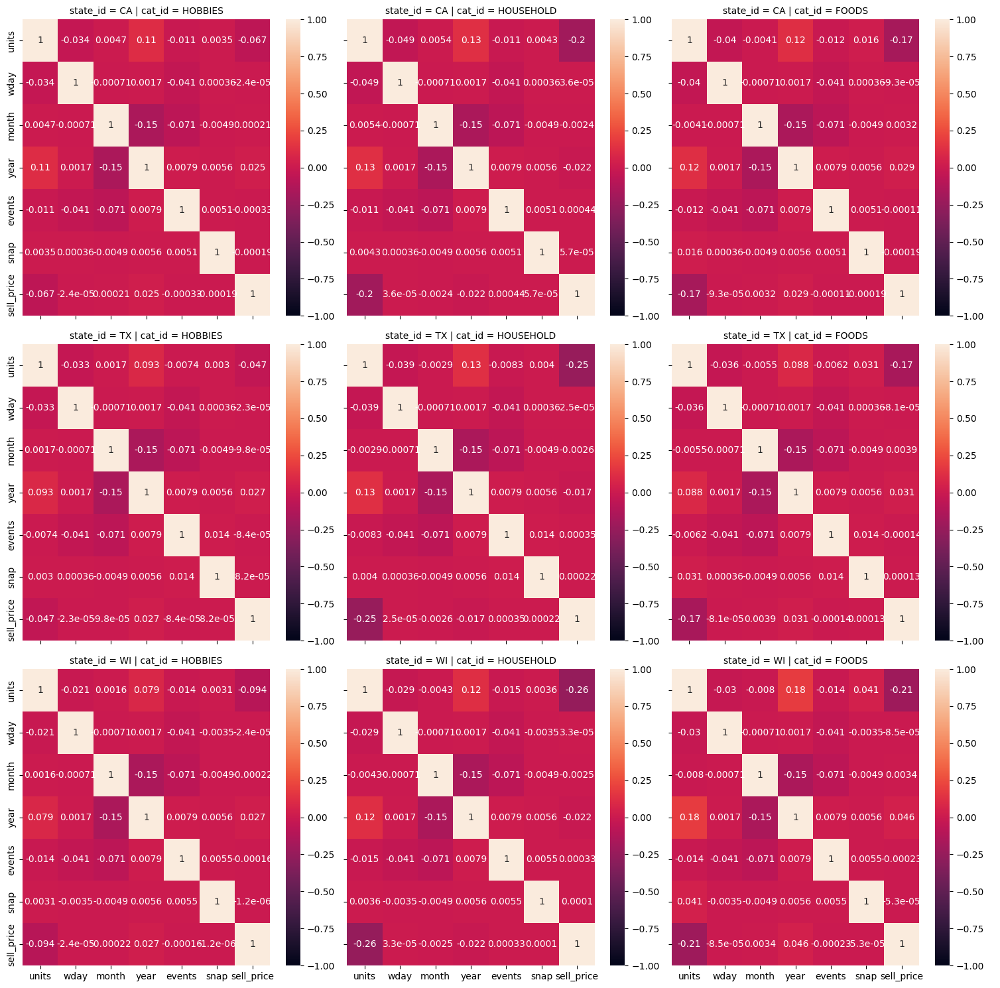

In [35]:
heatmaps(df)

Correlations between variables are not significant. The highest correlation is between units sold and sell price, though it does not exceed 0.3. 

## Clustering per item_id

Clustering will be done based on sales from 2016 to capture most recent sales trends.

In [ ]:
yr = df.loc[df.year==2016,'d'].unique()

In [7]:
clusters = opt_cl(10, sales.loc[:,yr])

[I 2026-02-17 08:42:35,190] A new study created in memory with name: no-name-9190eb90-c491-476c-889b-1dcf10a50fd5
[I 2026-02-17 08:43:39,572] Trial 3 finished with value: 0.8505077280630072 and parameters: {'n_clusters': 2, 'random_state': 42}. Best is trial 3 with value: 0.8505077280630072.
[I 2026-02-17 08:43:41,105] Trial 2 finished with value: 0.51778888668498 and parameters: {'n_clusters': 5, 'random_state': 42}. Best is trial 3 with value: 0.8505077280630072.
[I 2026-02-17 08:43:41,632] Trial 7 finished with value: 0.22731258091166937 and parameters: {'n_clusters': 10, 'random_state': 42}. Best is trial 3 with value: 0.8505077280630072.
[I 2026-02-17 08:43:43,238] Trial 6 finished with value: 0.3051924361941108 and parameters: {'n_clusters': 8, 'random_state': 42}. Best is trial 3 with value: 0.8505077280630072.
[I 2026-02-17 08:43:45,960] Trial 1 finished with value: 0.3051924361941108 and parameters: {'n_clusters': 8, 'random_state': 42}. Best is trial 3 with value: 0.850507728

In [10]:
print(f'Score: {clusters["score"]}\nN_clusters:{len(np.unique(clusters["labels"]))}\nClusters per label 0: {len(sales)-clusters["labels"].sum()}\nCLusters per label 1: {clusters["labels"].sum()}')

Score: 0.8505077280630072
N_clusters:2
Clusters per label 0: 29915
CLusters per label 1: 575


Clustering divided series into 2 clusters with silhouette score 0.85.

In [ ]:
mapping = sales.iloc[:,:6].copy()
mapping['label'] = clusters['label']


In [71]:
mapping

,id,item_id,dept_id,cat_id,store_id,state_id,label
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,1
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,1
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,1
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,1
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,1
...,...,...,...,...,...,...,...
30485,FOODS_3_823_WI_3_validation,FOODS_3_823,FOODS_3,FOODS,WI_3,WI,1
30486,FOODS_3_824_WI_3_validation,FOODS_3_824,FOODS_3,FOODS,WI_3,WI,1
30487,FOODS_3_825_WI_3_validation,FOODS_3_825,FOODS_3,FOODS,WI_3,WI,1
30488,FOODS_3_826_WI_3_validation,FOODS_3_826,FOODS_3,FOODS,WI_3,WI,1


In [66]:
counts_per_cluster = mapping.iloc[:,1:].groupby(['label', 'state_id','cat_id','dept_id','store_id']).count()

In [67]:
counts_per_cluster.head(20)

item_id
label state_id cat_id    dept_id     store_id         
0     CA       FOODS     FOODS_1     CA_1            7
                                     CA_2            7
                                     CA_3            6
                                     CA_4            2
                         FOODS_2     CA_1            4
                                     CA_2            2
                                     CA_3            9
                         FOODS_3     CA_1           38
                                     CA_2           35
                                     CA_3           71
                                     CA_4            9
               HOBBIES   HOBBIES_1   CA_1            6
                                     CA_3            5
                                     CA_4            1
               HOUSEHOLD HOUSEHOLD_1 CA_1           11
                                     CA_2            2
                                     CA_3           40
                         HOUSEHOLD_2 CA_3            1
      TX       FOODS     FOODS_1     TX_1            1
                                     TX_2            4

In [184]:
# Clusters visualization on 2016 units 
pca = PCA(n_components=2,random_state=42)
tr = MinMaxScaler().fit_transform(pca.fit_transform(sales.loc[:,yr]))

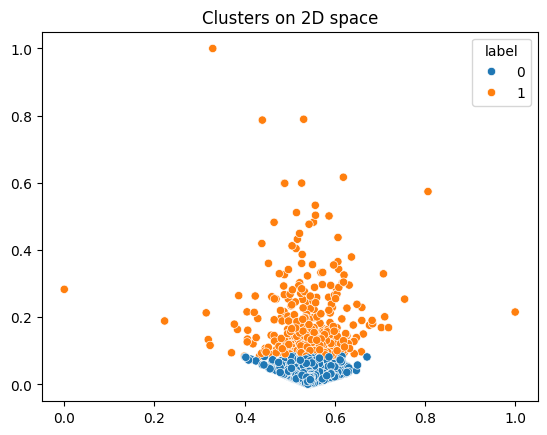

In [185]:
plt.title('Clusters on 2D space')
sns.scatterplot(y  = tr[:,0],x = tr[:,1], hue = mapping['label'])
plt.show()

The blue cluster contains series with low unit sales, the orange contains series with higher sales. The second cluster contains much less products.

In [45]:
ids_0 = mapping.loc[mapping.label==0,'id']
ids_1 = mapping.loc[mapping.label==1,'id']

In [ ]:
df.loc[df.id.isin(ids_0),:].describe()

,units,wm_yr_wk,wday,month,year,events,snap,sell_price
count,57227395.0000,57227395.0000,57227395.0000,57227395.0000,57227395.0000,57227395.0000,57227395.0000,45060961.0000
mean,0.8948,11339.1913,3.9974,6.3576,2013.2091,0.0826,0.3293,4.4600
std,2.3969,150.3742,2.0007,3.4588,1.5321,0.2828,0.4700,3.4114
min,0.0000,11101.0000,1.0000,1.0000,2011.0000,0.0000,0.0000,0.0100
25%,0.0000,11217.0000,2.0000,3.0000,2012.0000,0.0000,0.0000,2.2400
50%,0.0000,11333.0000,4.0000,6.0000,2013.0000,0.0000,0.0000,3.4800
75%,1.0000,11448.0000,6.0000,9.0000,2015.0000,0.0000,1.0000,5.8800
max,648.0000,11613.0000,7.0000,12.0000,2016.0000,2.0000,1.0000,107.3200


In [ ]:
df.loc[~df.id.isin(ids_0),:].describe()

,units,wm_yr_wk,wday,month,year,events,snap,sell_price
count,1099975.0000,1099975.0000,1099975.0000,1099975.0000,1099975.0000,1099975.0000,1099975.0000,966996.0000
mean,13.1715,11339.1913,3.9974,6.3576,2013.2091,0.0826,0.3293,1.9870
std,18.6729,150.3742,2.0007,3.4588,1.5321,0.2828,0.4700,1.7719
min,0.0000,11101.0000,1.0000,1.0000,2011.0000,0.0000,0.0000,0.0500
25%,0.0000,11217.0000,2.0000,3.0000,2012.0000,0.0000,0.0000,0.9800
50%,8.0000,11333.0000,4.0000,6.0000,2013.0000,0.0000,0.0000,1.5000
75%,18.0000,11448.0000,6.0000,9.0000,2015.0000,0.0000,1.0000,2.4800
max,763.0000,11613.0000,7.0000,12.0000,2016.0000,2.0000,1.0000,23.9800


## Seasonality check per clusters

In [ ]:
# Random choice of 2 ids per dept in each cluster
random.seed(42)
samples = {}
for c in mapping.label.unique():
    s = []
    for d in mapping.loc[mapping.label==c,'dept_id'].unique():
        s.extend(random.choices(mapping.loc[(mapping.label==c)&(mapping.dept_id==d),'id'].tolist(), k=2))
    samples[c] = s


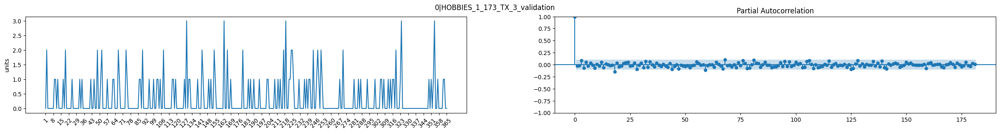

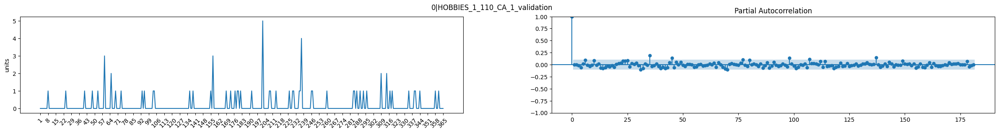

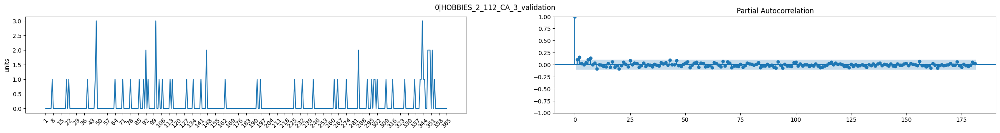

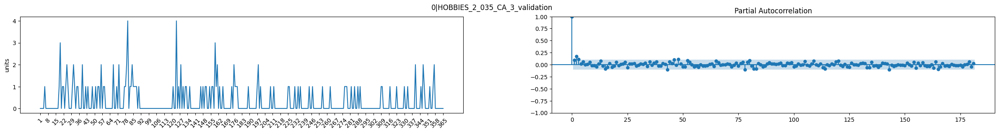

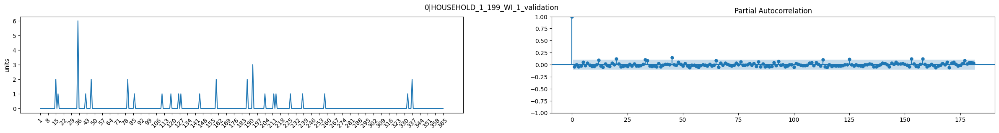

...

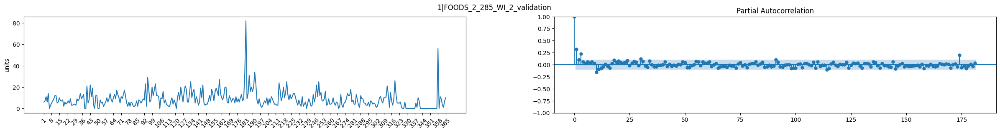

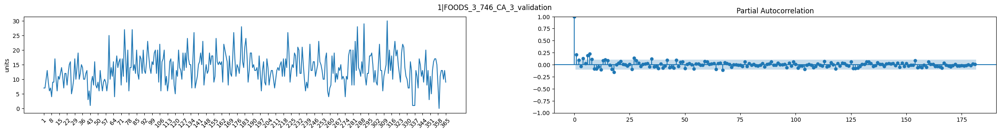

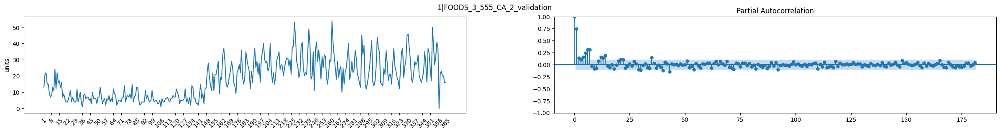

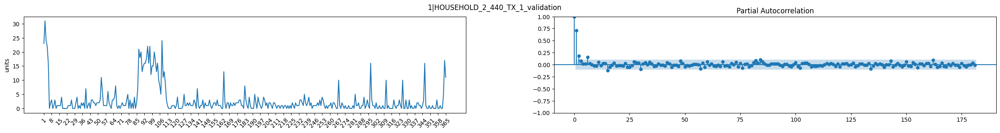

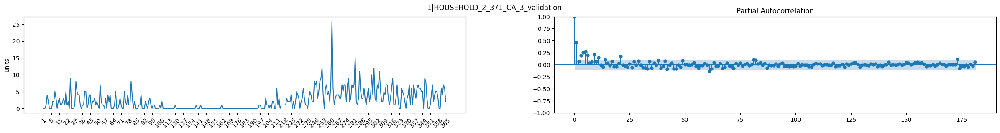

In [203]:
# One year = 2015
plot_season(samples, df.loc[df.year==2015,:])

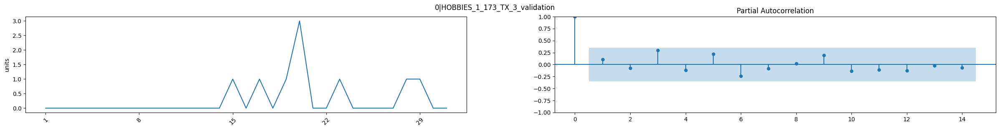

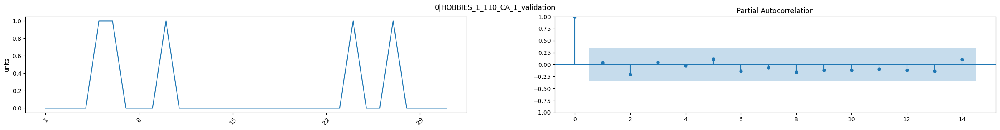

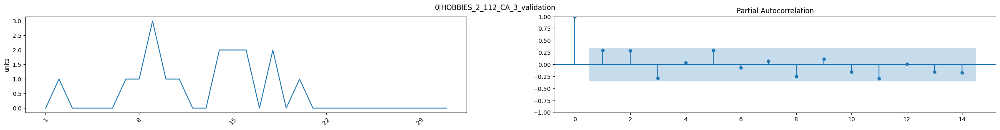

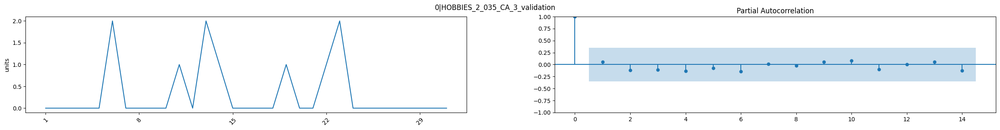

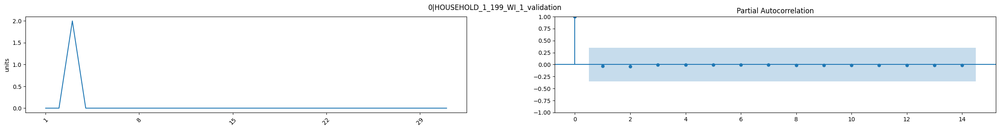

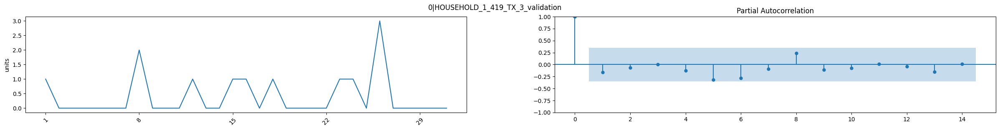

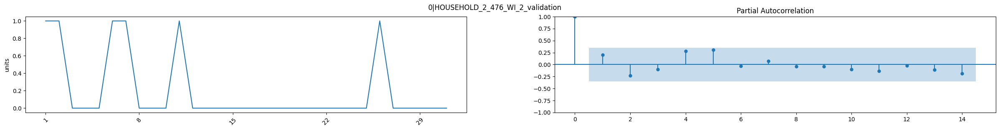

WARNING - (py.warnings._showwarnmsg) - c:\Users\krystyna_furgacz1\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\regression\linear_model.py:1490: ValueWarning: Matrix is singular. Using pinv.
  warnings.warn("Matrix is singular. Using pinv.", ValueWarning)



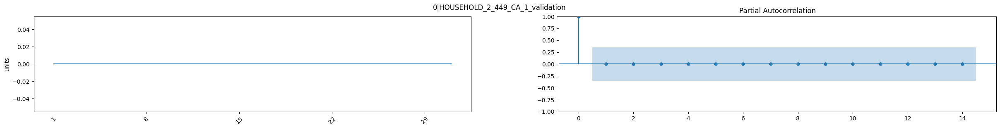

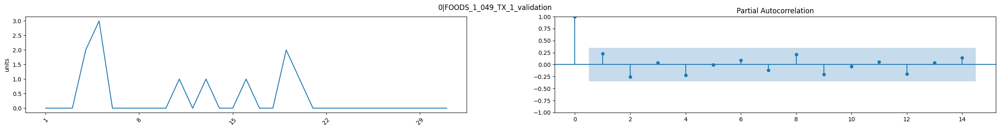

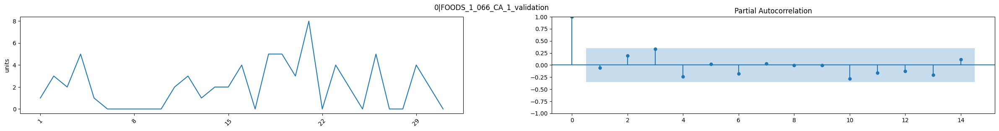

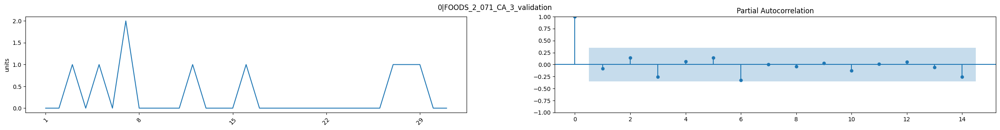

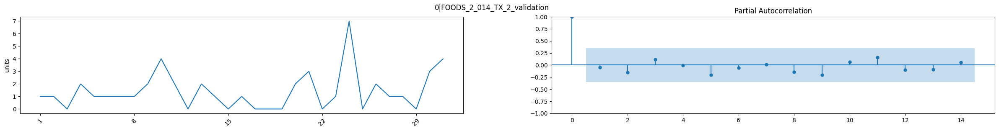

...

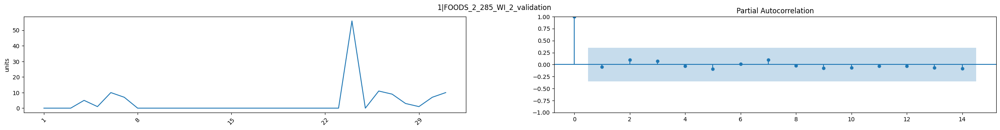

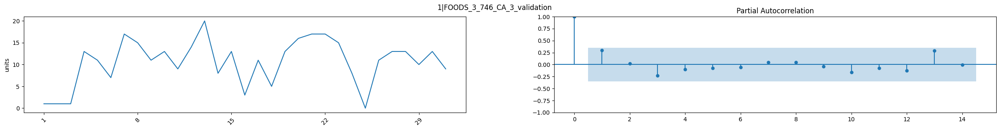

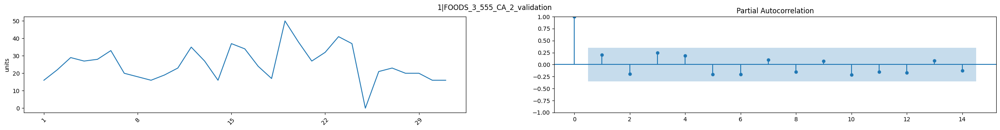

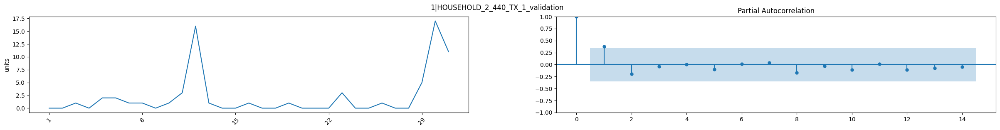

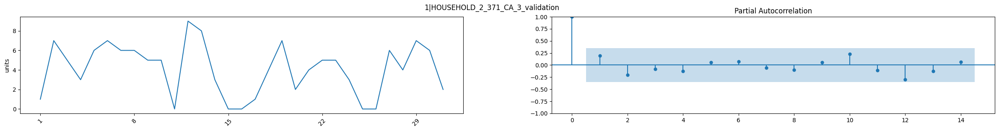

In [204]:
# One year = 2015
plot_season(samples, df.loc[(df.year==2015)&(df.month==12),:])

*   There are no visible yearly/monthly/weekly seasonality patterns on presented sample, though there may exist some in other series looking at general charts from previous section
*   There are trends visible for some of the series
*   Some products were not sold for many days and their history is limited

## Stationarity check

In [207]:
p_v = []
for i in range(len(sales)):
    p_v.append(adfuller(sales.iloc[i,6:])[1])


In [208]:
sales['pv'] = p_v

In [212]:
sales['label'] = mapping['label']

In [217]:
# % of non-stationary series
sales[['label','state_id','dept_id','pv']].groupby(['label','state_id','dept_id']).apply(lambda x: (x>0.05).sum()/len(x))

pv
label state_id dept_id           
0     CA       FOODS_1     0.1064
               FOODS_2     0.2459
               FOODS_3     0.1741
               HOBBIES_1   0.1264
               HOBBIES_2   0.0201
               HOUSEHOLD_1 0.2340
               HOUSEHOLD_2 0.0767
      TX       FOODS_1     0.0455
               FOODS_2     0.1085
               FOODS_3     0.1156
               HOBBIES_1   0.0916
               HOBBIES_2   0.0201
               HOUSEHOLD_1 0.1863
               HOUSEHOLD_2 0.0525
      WI       FOODS_1     0.0648
               FOODS_2     0.2155
               FOODS_3     0.1555
               HOBBIES_1   0.0729
               HOBBIES_2   0.0157
               HOUSEHOLD_1 0.1838
               HOUSEHOLD_2 0.0485
1     CA       FOODS_1     0.3333
               FOODS_2     0.2143
               FOODS_3     0.2292
               HOBBIES_1   0.3636
               HOUSEHOLD_1 0.5745
               HOUSEHOLD_2 1.0000
      TX       FOODS_1     0.5000
               FOODS_2     0.0000
               FOODS_3     0.2500
               HOBBIES_1   1.0000
               HOUSEHOLD_1 0.3478
               HOUSEHOLD_2 0.0000
      WI       FOODS_1     0.3333
               FOODS_2     0.5172
               FOODS_3     0.2131
               HOUSEHOLD_1 0.1667

Almost each department contains non-stationary series in both clusters.


## Preprocessing

In this section ML-suited dataset will be created for training future models.

### Handling missing prices

Due to many missing prices, new column with missing price indicator will be added. Additionally, due to negatve correlation between price and sales, NaN price values will be replaced by 999 as this number is far above actual maximum pricee from the whole dataset.

In [11]:
# Adding 'missing price' column

df['missing_price'] = df['sell_price'].isna().astype(int)
df_eval['missing_price'] = df_eval['sell_price'].isna().astype(int)

In [12]:
# Imputting NaNs by 999

df.loc[df.sell_price.isna(),'sell_price'] = 999
df_eval.loc[df_eval.sell_price.isna(),'sell_price'] = 999

### Converting date to pd.datetime format

In [13]:
# Converting date to pd.datetime format
df.date = pd.to_datetime(df.date)
df_eval.date = pd.to_datetime(df_eval.date)

### Adding lag 28 feature

Sales from past 28 days will be added as feature as for some products sales patterns may repeat week over week.

In [ ]:
df2 = df.copy()
df_eval2 = df_eval.copy()

In [ ]:
df2['lag28'] = df['units'].shift(28*len(df.id.unique()))
df_eval2['lag28'] = df_eval['units'].shift(28*len(df.id.unique()))

In [ ]:
df2 = df2.iloc[28*len(df.id.unique()):,:]
df_eval2 = df_eval2.iloc[28*len(df.id.unique()):,:]

df2['lag28'] = df2['lag28'].astype('int16')
df_eval2['lag28'] = df_eval2['lag28'].astype('int16')

### Converting to appropriate datatypes

In [ ]:
df2[['units','wday','month','year','events','snap','missing_price']] = df2[['units','wday','month','year','events','snap','missing_price']].astype('int16')
df_eval2[['units','wday','month','year','events','snap','missing_price']]= df_eval2[['units','wday','month','year','events','snap','missing_price']].astype('int16')

df2[['sell_price']] = df2[['sell_price']].astype('float16')
df_eval2[['sell_price']] = df_eval2[['sell_price']].astype('float16')

### Next steps - preprocessing pipeline

In the pipeline, below steps will be applied:


1. Columns:

*   wm_yr_wk
*   weekday
*   event_type
*   d
*   cat_id
*   item_id
*   store_id
*   state_id
*   dept_id


    Will be removed due to there already exist date-related and event-related features and each series id is created based on state and department.

2. Features will be scaled using MinMaxScaler

3. Final dataset will consist of following features:
    *   Units - target
    *   Lag28
    *   Wday
    *   Month 
    *   Year
    *   Events
    *   Sell price
    *   Snap
    *   Missing price

    For sales forecasting, historical sales and pricing should be the most important features, however impact of the date features and events may be also beneficial, e.g. for seasonal products.


In [5]:
transformer = ColumnTransformer([
    ('scaler', MinMaxScaler(),['lag28','wday', 'month', 'year', 'events','sell_price'])
], remainder = 'passthrough')

In [6]:
# Pipeline for scale-dependent models
pipe = Pipeline([
    ('selector', ColumnSelector()),
    ('tr', transformer),
    ('df', DataframeBuilder())
])

In [4]:
# Pipeline for scale-independent models
pipe2 = Pipeline([
    ('selector', ColumnSelector())
])

### Train test split

In [22]:
# Train test split - test size 28 days per series

train = df2.iloc[:-28*len(df.id.unique()),:]
test = df2.iloc[-28*len(df.id.unique()):,:]

In [6]:
# Train_test for validation prediciton

train_test = pd.concat([train, test])

In [ ]:
# Validation

val = df_eval2.iloc[-28*len(df2.id.unique()):,:]
val['id'] = val['id'].apply(lambda x: x.replace('evaluation','validation'))

In [13]:
# True values

true = test.loc[:,['id','date','units']].sort_values(by=['id','date'])
true_val = val.loc[:,['id','date','units']].sort_values(by=['id','date'])

In [ ]:
# Preprocessed train, test

train_tr = pipe.fit_transform(train)
test_tr = pipe.transform(test)

In [10]:
# Preprocessed for validation

train_test_tr = pipe.fit_transform(df2)
val_tr = pipe.transform(val)

### Evaluation dataset creation

In [94]:
evaluation = create_eval(val, calendar, snap)

In [ ]:
# Preprocessed for evaluation

train_test_val_tr = pipe.fit_transform(test)
eval_tr = pipe.transform(evaluation)

### CV splitter

Cross valiation training will be done on last 3 years due increasing trend, and testing will be on year 2016.

In [8]:
splitter = SlidingWindowSplitter(fh = range(1,28*len(train.id.unique())+1), step_length=28*len(train.id.unique()), window_length=33478020, initial_window=54058770)
split = []
for i,j in splitter.split(train):
    split.append((i,j))

# **Baseline (dummy) prediction**

For baseline (dummy) prediction, two models will be evaluated on the test set:

*   SeasonalNaive
*   Exponential Smoothing
*   Poisson Regression

## Prediction of the test set

In [136]:
sf = StatsForecast( 
    models=[
        SeasonalNaive(season_length=7),
        HoltWinters(season_length=7,
                    error_type="A",
                    alias="HoltWintersA"),
        SklearnModel(PoissonRegressor())
    ],
    freq='D', 
    n_jobs=-1,
)

naive = sf.forecast(df = train_tr,
                    h=28,
                    X_df = test_tr[test_tr.columns.difference(['units'])],
                    id_col="id",
                    time_col="date",
                    target_col="units")

In [ ]:
naive.iloc[:,-3:] = np.round(naive.iloc[:,-3:])

In [56]:
idx = random.choices(train.id.unique(),k=10)
filter = train_test.id.isin(idx)&(train_test.year==2016)

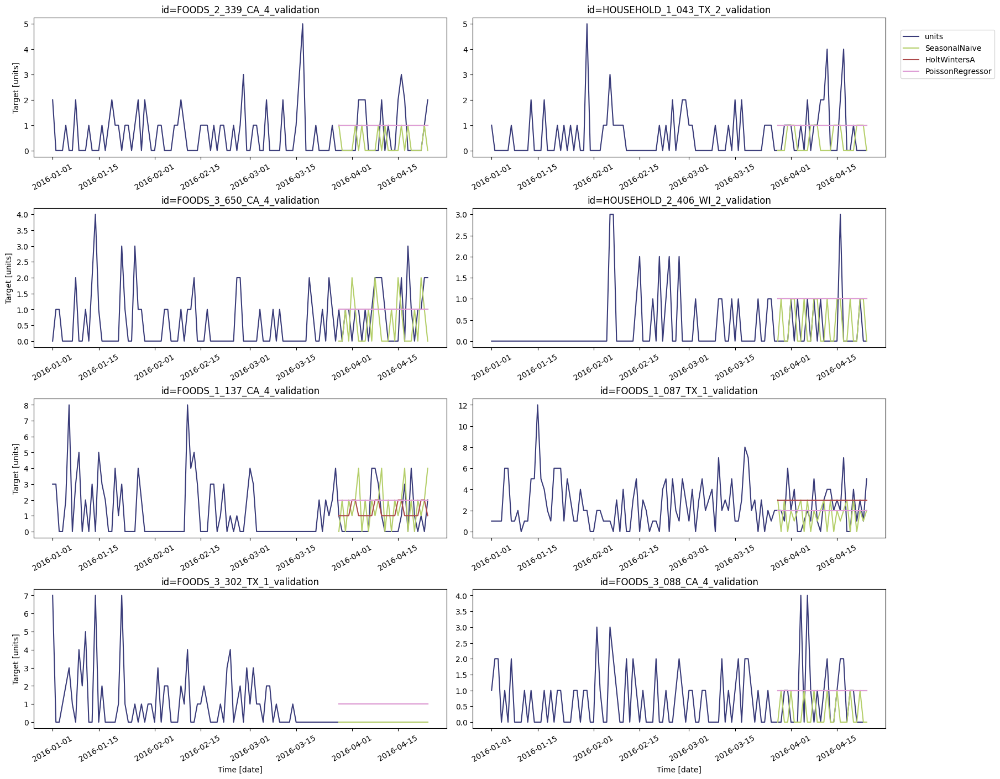

In [ ]:
# Random forecasts visualisation vs actuals
sf.plot(train_test.loc[filter,['id','date','units']],
        naive.loc[naive.id.isin(idx),:],
        id_col="id",
        time_col="date",
        target_col="units")

In [46]:
naive_scores = wrmsse(test, naive, train)
naive_scores

,SeasonalNaive,HoltWintersA,PoissonRegressor
WRMSSE,1.3402,1.1547,1.3023


Naive score on the test set is the best for Holt-Winters model. 

## **Prediction of the validation set**

In [ ]:
sf = StatsForecast( 
    models=[
        HoltWinters(season_length=7,
                    error_type="A",
                    alias="HoltWintersA")
    ],
    freq='D', 
    n_jobs=-1,
)

sf.fit(df = train_test_tr,
                    id_col="id",
                    time_col="date",
                    target_col="units")

naive_val = sf.predict(h=28, X_df = val_tr.loc[:,val_tr.columns.difference(['units'])])


In [ ]:
naive_val.iloc[:,-1:] = np.round(naive_val.iloc[:,-1:])

In [17]:
naive_var_score = wrmsse(val, naive_val, train_test_tr)
naive_var_score

,HoltWintersA
WRMSSE,1.1259


Predicion score on the validation set is slightly better than on the test set.

## **Prediction of the evaluation set**

In [ ]:
sf.fit(df = train_test_val_tr,
                    id_col="id",
                    time_col="date",
                    target_col="units")




In [98]:
naive_eval = sf.predict(h=28, X_df =eval_tr.loc[:,eval_tr.columns.difference(['units'])])

In [ ]:
naive_eval.iloc[:,-1:] = np.round(naive_eval.iloc[:,-1:])

In [101]:
fc_dummy = make_forecast(naive_val, naive_eval)

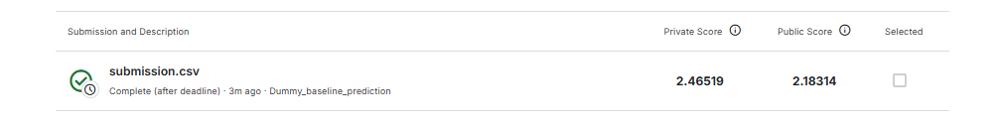

Dummy prediction on the evalutaion set has score 2.46/2.18, which means there is space for improvement.

# **Training on the subset of data**

## Creating a subset

For the subset, 15% of series will be taken per each record from counts_per_cluster dataframe.

In [ ]:
counts_per_cluster['subset'] = np.round(counts_per_cluster['item_id']*0.15)

In [74]:
counts_per_cluster['subset'].sum()

4638.0

In [ ]:
id_subset = mapping.loc[:,~mapping.columns.isin(['item_id'])].groupby(['label', 'state_id','cat_id','dept_id','store_id']).apply(lambda group: np.random.choice(group['id'].values, size = int(np.round(0.15*len(group))), replace = False))
id_subset


label  state_id  cat_id     dept_id      store_id
0      CA        FOODS      FOODS_1      CA_1        [FOODS_1_218_CA_1_validation, FOODS_1_018_CA_1...
                                         CA_2        [FOODS_1_085_CA_2_validation, FOODS_1_018_CA_2...
                                         CA_3                            [FOODS_1_200_CA_3_validation]
                                         CA_4                            [FOODS_1_085_CA_4_validation]
                            FOODS_2      CA_1                            [FOODS_2_197_CA_1_validation]
                                                                           ...                        
1      WI        HOUSEHOLD  HOUSEHOLD_1  WI_2        [HOUSEHOLD_1_104_WI_2_validation, HOUSEHOLD_1_...
                                         WI_3        [HOUSEHOLD_1_002_WI_3_validation, HOUSEHOLD_1_...
                            HOUSEHOLD_2  WI_1        [HOUSEHOLD_2_138_WI_1_validation, HOUSEHOLD_2_...
                       

In [76]:
id_subset2 = np.concatenate(id_subset.values)
len(id_subset2)

4638

In [80]:
train_subset = train.loc[train.id.isin(id_subset2),:]

In [81]:
test_subset = test.loc[test.id.isin(id_subset2),:]

In [246]:
val_subset = val.loc[val.id.isin(id_subset2),:]

In [20]:
# Subset splitter

splitter_subset = SlidingWindowSplitter(fh = range(1,28*len(train_subset.id.unique())+1), step_length=28*len(train_subset.id.unique()), window_length=5078610, initial_window=8223174)
split_subset = []
for i,j in splitter_subset.split(train_subset):
    split_subset.append((i,j))

## Dummy prediction on the subset

In [23]:
sf = StatsForecast( 
    models=[
        HoltWinters(season_length=7,
                    error_type="A",
                    alias="HoltWintersA")
    ],
    freq='D', 
    n_jobs=-1,
)

naive_subset = sf.forecast(df = train_subset[['id','date','units']],
                    h=28,
                    id_col="id",
                    time_col="date",
                    target_col="units")

In [ ]:
naive_subset.iloc[:,-1:] = np.round(naive_subset.iloc[:,-1:])

In [25]:
wrmsse(test_subset,naive_subset,train_subset)

,HoltWintersA
WRMSSE,1.1528


## Training various models - univariate, classic multivariate

Proepht model will be tested for univariate and multivariate case due to capturing multiple seasonalities.

In [ ]:
# Univariate training
results_uv = prop_opt(train_subset, test_subset, 3, split_subset, 'u', pipe)

Optimizing
Predicting
Completed


In [230]:
results_uv['WRMSEE']

,Prophet
WRMSSE,1.1709


In [21]:
# Multivariate training
results_mv = prop_opt(train_subset, test_subset, 3, split_subset, 'm', pipe2)

Optimizing
Fitting fold
Predicting fold
Fitting fold
Predicting fold
Fitting fold
Predicting fold
Fitting fold
Predicting fold
Fitting fold
Predicting fold
Fitting fold
Predicting fold
Fitting fold
Predicting fold
Fitting fold
Predicting fold
Fitting fold
Predicting fold
Best params: {'daily_seasonality': False, 'weekly_seasonality': 4, 'yearly_seasonality': 15, 'seasonality_mode': 'additive', 'changepoint_prior_scale': 0.07885330158077582, 'seasonality_prior_scale': 1.5683852581586646, 'holidays_prior_scale': 0.5902552855603126, 'changepoint_range': 0.9299264218662402, 'add_country_holidays': {'country_name': 'US'}, 'freq': 'D'}
Predicting
Completed


In [22]:
results_mv['WRMSEE']

,Prophet
WRMSSE,1.1583


Overall performance of both Prophet models is similar to dummy prediction, which is not an improvement. This model is not the best choice due to seasonality and trend setup is the same for all series, which does not make sense for such variety of products.

# **ML approach**

For ML models, following models will be trained and evaluated:
*   LSTM
*   LigthGBM

LSTM would be a good choice due to its memory of past sales, and LightGBM model is suitable for large datasets, handles categorical features and does not require scaling.

## LSTM

In [4]:
# Creating features lists

static = test[['id']].drop_duplicates().reset_index(drop = True)
static = pd.concat([static,pd.DataFrame(OneHotEncoder(sparse_output=False, dtype='int8').fit_transform(static), columns = ['id_'+str(n) for n in static.values])], axis = 1)

In [5]:
static = pd.read_parquet('static.parquet')

In [6]:
futr = [ 'wday', 'month', 'year','events', 'snap', 'sell_price', 'missing_price', 'lag28']

In [7]:
f = [futr, static]

In [ ]:
results_lstm = lstm_opt(train, test, 7, split, pipe2, f)

In [13]:
results_lstm['WRMSEE']

,LSTM
WRMSSE,1.6403


In [19]:
idx2 = np.random.choice(train.id.unique(), size = 8)

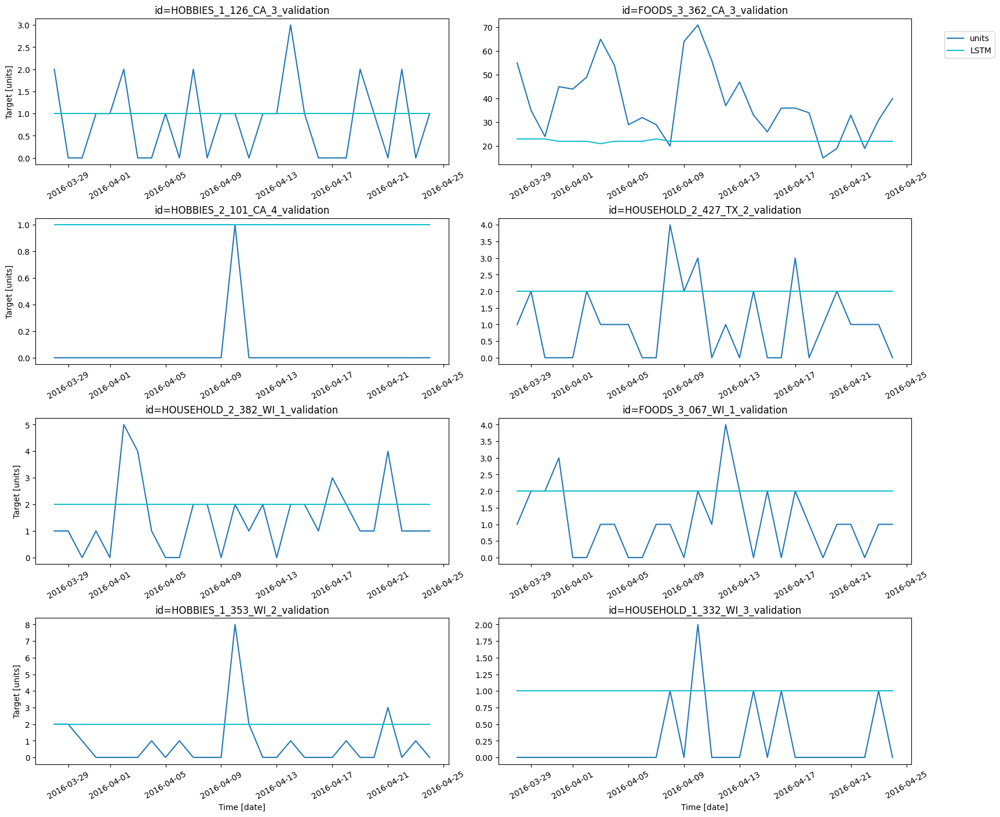

In [31]:
plot_series(test.loc[test.id.isin(idx2),['id','date','units']],
            results_lstm['pred'].loc[results_lstm['pred'].id.isin(idx2),:],
            id_col="id",
            time_col="date",
            target_col="units")

LSTM model produces flat forecasts looking at above sample, and WRMSSE is higher than dummy prediction.  It can be further improved by tuning hyperparameters, however it will not be developed further due to high computational cost.

## LightGBM

In [ ]:
# Converting missing prices to NaNs as model handles them
train.loc[train.sell_price==999,'sell_price'] = np.nan

In [ ]:
# Selecting only relevant features, dropping 'missing price' column and chnaging data formats
X_train, y_train = format(train)
X_test, y_test = format(test)

In [16]:
results_lgb_1 = lgb_opt(train, test, X_train, y_train, X_test, y_test, 7, split)

Optimization start
Best params:  {'n_estimators': 500, 'num_leaves': 150, 'max_depth': 11, 'min_split_gain': 0.10401360423556216, 'min_child_weight': 5.461, 'min_child_samples': 30, 'learning_rate': 0.291179542051722, 'subsample': 0.9, 'colsample_bytree': 1.0, 'reg_alpha': 8.948273504276488, 'reg_lambda': 5.978999788110851, 'random_state': 42, 'n_jobs': -1, 'verbose': -1}
Predicting
Completed


In [17]:
results_lgb_1['WRMSSE']

,LGBM
WRMSSE,1.1572


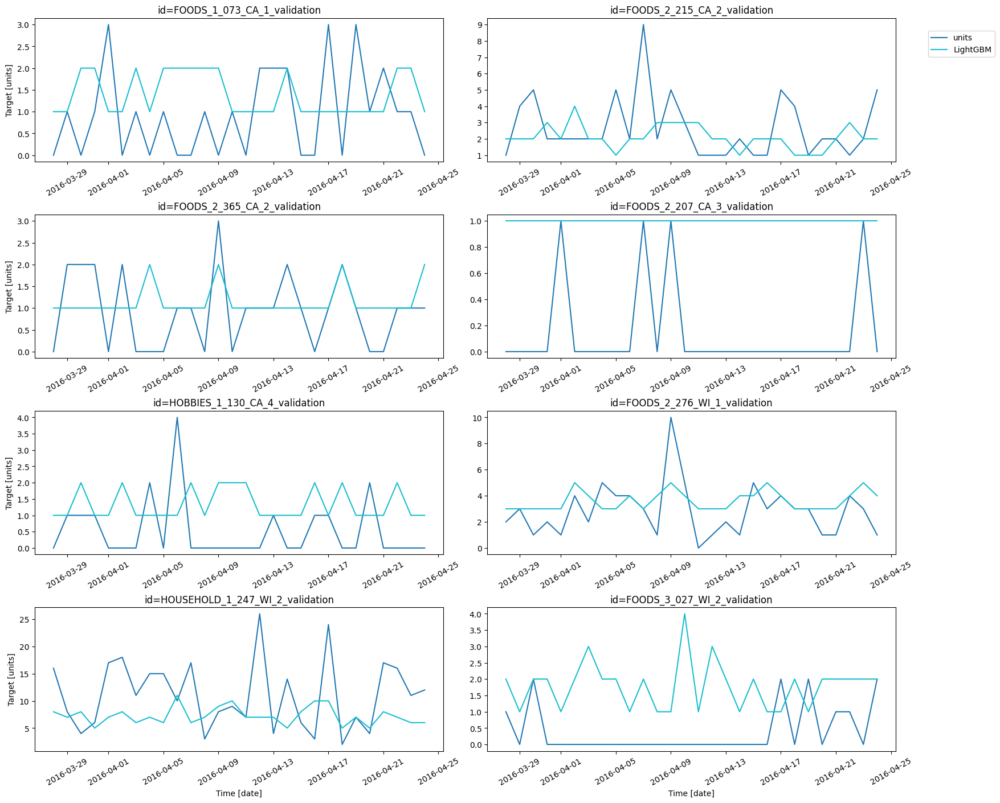

In [20]:
plot_series(test.loc[test.id.isin(idx2),['id','date','units']],
            results_lgb_1['pred'].loc[results_lgb_1['pred'].id.isin(idx2),:],
            id_col="id",
            time_col="date",
            target_col="units")

LightGBM model performs better on the test set than LSTM model.

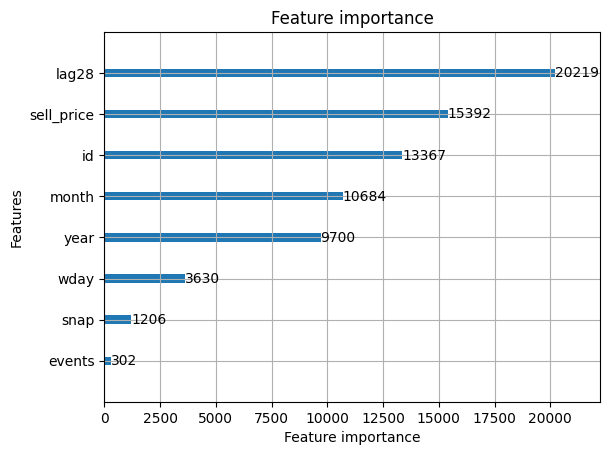

In [21]:
lgb.plot_importance(results_lgb_1['model'])
plt.show()

Besides id feature, sell_price and lag28 have the highest importance from the model, which is reasonable.

### Feature engineering

Features describing rolling mean and rolling std from past 28 days will be added to the dataset. Column 'events' will be removed due to low importance.

In [ ]:
train2 = add_rolling(df, train, 28)
test2 = add_rolling(df, test, 28)

In [ ]:
val2 = add_rolling(df_eval, val, 28)

In [ ]:
X_train2, _ = format(train2, ext=True)
X_test2, _ = format(test2, ext=True)

In [90]:
X_val, y_val = format(val2, ext=True)

In [71]:
results_lgb_2 = lgb_opt(train2, test2, X_train2, y_train, X_test2, y_test, 7, split)

Optimization start
Best params:  {'n_estimators': 1000, 'num_leaves': 63, 'max_depth': 9, 'min_split_gain': 0.009045457782107613, 'min_child_weight': 3.251, 'min_child_samples': 48, 'learning_rate': 0.10926826367778447, 'subsample': 0.9, 'colsample_bytree': 0.7, 'reg_alpha': 2.8093450968738076, 'reg_lambda': 5.426960831582485, 'random_state': 42, 'n_jobs': -1, 'verbose': -1}
Predicting
Completed


In [72]:
results_lgb_2['WRMSSE']

,LGBM
WRMSSE,1.0876


Tuning the model improved metric on the test dataset.

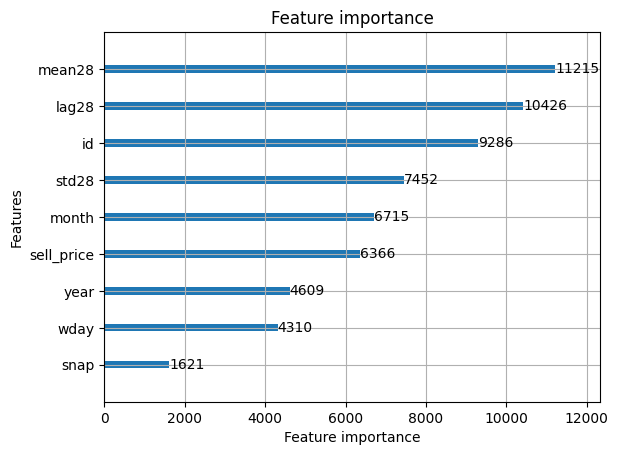

In [73]:
lgb.plot_importance(results_lgb_2['model'])
plt.show()

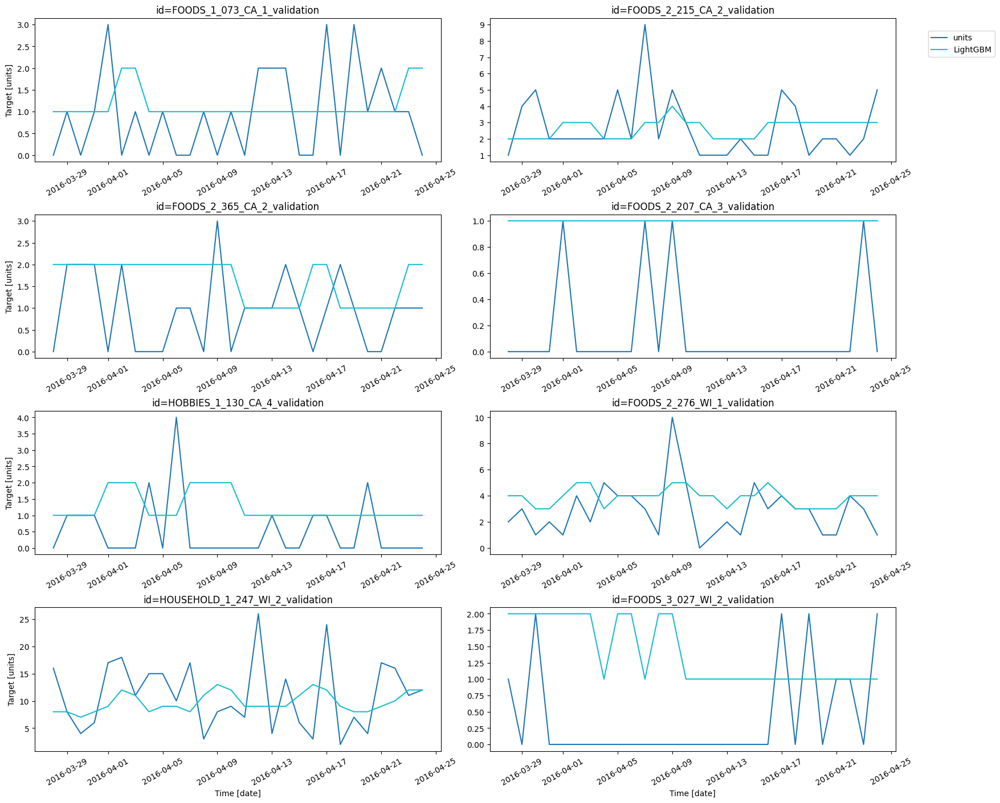

In [76]:
plot_series(test2.loc[test2.id.isin(idx2),['id','date','units']],
            results_lgb_2['pred'].loc[results_lgb_2['pred'].id.isin(idx2),:],
            id_col="id",
            time_col="date",
            target_col="units")

In [12]:
idx3 = np.random.choice(X_train2.id.unique(), size = 5)

FOODS_3_381_CA_1_validation


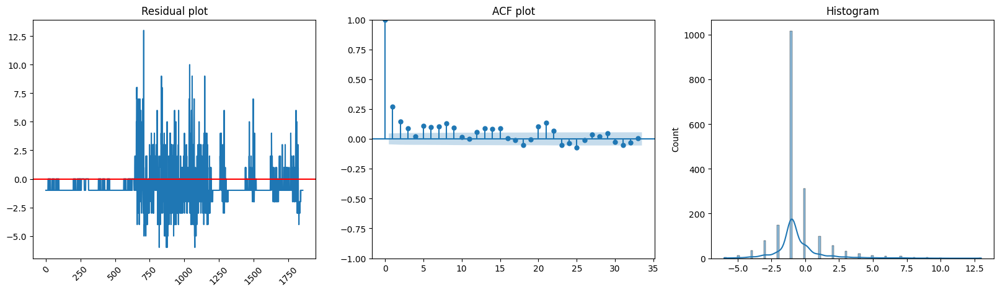

Mean of residuals: -0.60635
DW statistic: 1.29932
Normality Shapiro test p-value: 0.00000
FOODS_3_385_TX_3_validation


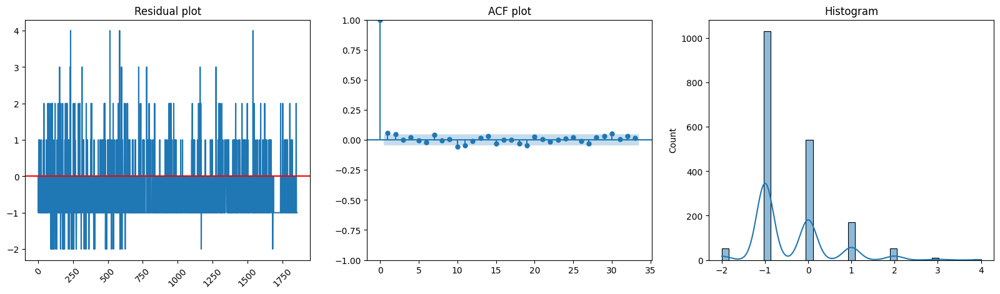

Mean of residuals: -0.43888
DW statistic: 1.50085
Normality Shapiro test p-value: 0.00000
FOODS_3_659_WI_1_validation


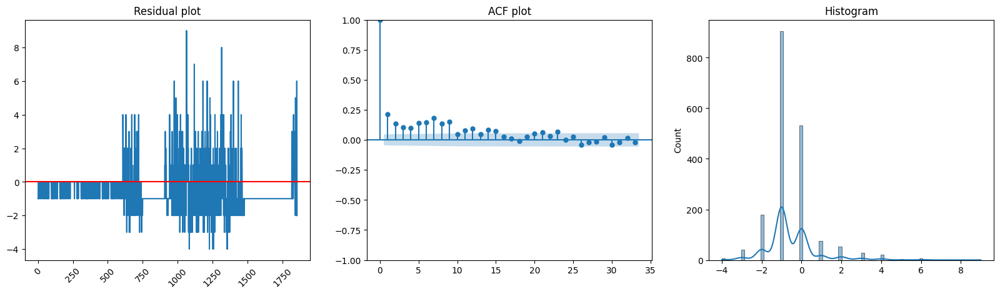

Mean of residuals: -0.53366
DW statistic: 1.32862
Normality Shapiro test p-value: 0.00000
FOODS_3_609_TX_3_validation


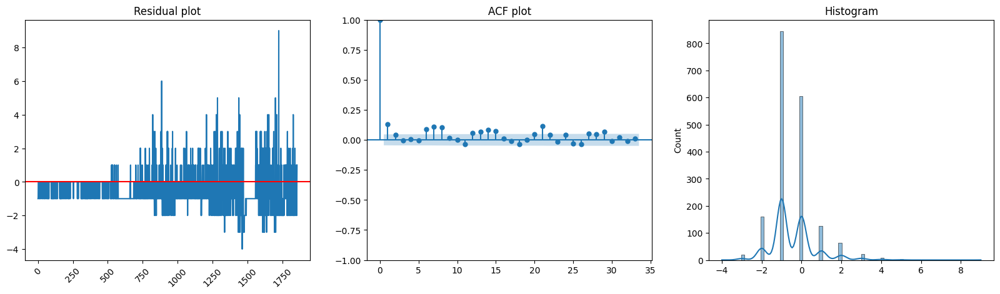

Mean of residuals: -0.45557
DW statistic: 1.48034
Normality Shapiro test p-value: 0.00000
FOODS_3_258_WI_3_validation


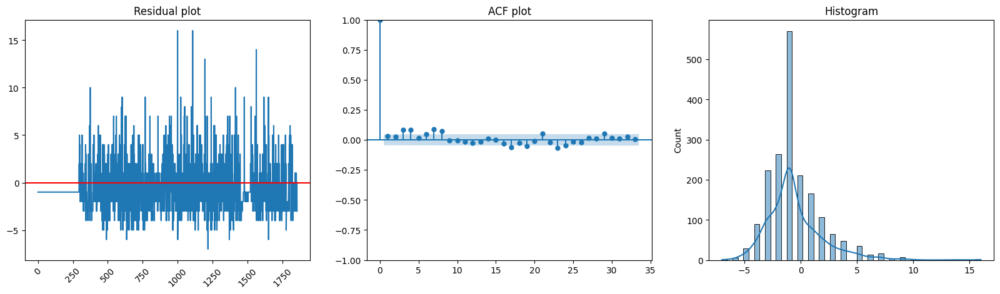

Mean of residuals: -0.53635
DW statistic: 1.84684
Normality Shapiro test p-value: 0.00000


In [26]:
for i in idx3:
    filt = X_train2.id==i
    print(i)
    residual_analysis(results_lgb_2['residuals'][filt])

### Prediction on the validation set

In [27]:
X_traintest = pd.concat([X_train2,X_test2])
y_traintest = pd.concat([y_train, y_test])

In [30]:
X_traintest['month'] = X_traintest['month'].astype('category')

In [40]:
results_lgb_2['model'].fit(X_traintest, y_traintest)

LGBMRegressor(colsample_bytree=0.7, learning_rate=0.10926826367778447,
              max_depth=9, min_child_samples=48, min_child_weight=3.251,
              min_split_gain=0.009045457782107613, n_estimators=1000, n_jobs=-1,
              num_leaves=63, random_state=42, reg_alpha=2.8093450968738076,
              reg_lambda=5.426960831582485, subsample=0.9, verbose=-1)

In [ ]:
pred_val_lgb = np.round(results_lgb_2['model'].predict(X_val))

In [ ]:
p_val = pd.DataFrame({
    'id':X_val['id'].values,
    'units': pred_val_lgb
})

In [112]:
wrmsse(val, pred_val_lgb, df_eval)

,LGBM
WRMSSE,1.0082


### Prediction on the evaluation set

In [ ]:
evaluation['mean28'] = np.nan
evaluation['std28'] = np.nan

X_eval, _ = format(evaluation, ext=True)

In [113]:
X, y = pd.concat([X_traintest, X_val]), pd.concat([y_traintest, y_val])

In [50]:
X[['wday','id','month','snap']] = X[['wday','id','month','snap']].astype('category')
X_eval[['wday','id','month','snap']] = X_eval[['wday','id','month','snap']].astype('category')
X['id'] = X['id'].apply(
        lambda x: x.replace('validation', 'evaluation'))

In [52]:
results_lgb_2['model'].fit(X, y)

LGBMRegressor(colsample_bytree=0.7, learning_rate=0.10926826367778447,
              max_depth=9, min_child_samples=48, min_child_weight=3.251,
              min_split_gain=0.009045457782107613, n_estimators=1000, n_jobs=-1,
              num_leaves=63, random_state=42, reg_alpha=2.8093450968738076,
              reg_lambda=5.426960831582485, subsample=0.9, verbose=-1)

In [ ]:
insert_vals(X,y,X_eval,0)
X_eval

,id,lag28,wday,month,year,snap,sell_price,mean28,std28
date,,,,,,,,,
2016-05-23,HOBBIES_1_001_CA_1_evaluation,0,3,5,2016,0,8.3800001144,1.1785714286,1.4156158568
2016-05-23,HOBBIES_1_002_CA_1_evaluation,0,3,5,2016,0,3.9700000286,0.2500000000,0.5181877252
2016-05-23,HOBBIES_1_003_CA_1_evaluation,0,3,5,2016,0,2.9700000286,0.7500000000,0.9670497325
2016-05-23,HOBBIES_1_004_CA_1_evaluation,0,3,5,2016,0,4.6399998665,1.7500000000,1.7976321875
2016-05-23,HOBBIES_1_005_CA_1_evaluation,1,3,5,2016,0,2.8800001144,1.3928571429,1.1001442907
...,...,...,...,...,...,...,...,...,...
2016-06-19,FOODS_3_823_WI_3_evaluation,1,2,6,2016,0,2.9800000191,NaN,NaN
2016-06-19,FOODS_3_824_WI_3_evaluation,0,2,6,2016,0,2.4800000191,NaN,NaN
2016-06-19,FOODS_3_825_WI_3_evaluation,2,2,6,2016,0,3.9800000191,NaN,NaN


In [121]:
hist = pd.DataFrame({
    'id': X['id'].values,
    'units': y['units'].values
})

In [ ]:
pred_lgb_eval2 = recursive(X_eval, results_lgb_2['model'], hist)

                                  id        units
0      HOBBIES_1_001_CA_1_evaluation 1.0000000000
1      HOBBIES_1_002_CA_1_evaluation 0.0000000000
2      HOBBIES_1_003_CA_1_evaluation 1.0000000000
3      HOBBIES_1_004_CA_1_evaluation 2.0000000000
4      HOBBIES_1_005_CA_1_evaluation 1.0000000000
...                              ...          ...
30485    FOODS_3_823_WI_3_evaluation 1.0000000000
30486    FOODS_3_824_WI_3_evaluation 0.0000000000
30487    FOODS_3_825_WI_3_evaluation 1.0000000000
30488    FOODS_3_826_WI_3_evaluation 1.0000000000
30489    FOODS_3_827_WI_3_evaluation 1.0000000000

[30490 rows x 2 columns]
                                  id        units
0      HOBBIES_1_001_CA_1_evaluation 1.0000000000
1      HOBBIES_1_002_CA_1_evaluation 0.0000000000
2      HOBBIES_1_003_CA_1_evaluation 1.0000000000
3      HOBBIES_1_004_CA_1_evaluation 2.0000000000
4      HOBBIES_1_005_CA_1_evaluation 1.0000000000
...                              ...          ...
30485    FOODS_3_823_WI_

In [ ]:
# Creating submission files

make_forecast(p_val, pred_lgb_eval2, 'submission2.csv')

,id,F1,F2,F3,F4,F5,F6,F7,F8,F9,...,F19,F20,F21,F22,F23,F24,F25,F26,F27,F28
0,HOBBIES_1_001_CA_1_validation,1.0000,1.0000,1.0000,2.0000,2.0000,1.0000,1.0000,8.0000,1.0000,...,9.0000,1.0000,1.0000,1.0000,2.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,HOBBIES_1_002_CA_1_validation,2.0000,5.0000,1.0000,4.0000,1.0000,1.0000,1.0000,1.0000,1.0000,...,2.0000,13.0000,1.0000,2.0000,1.0000,1.0000,1.0000,1.0000,3.0000,2.0000
2,HOBBIES_1_003_CA_1_validation,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,2.0000,1.0000,1.0000,...,1.0000,2.0000,1.0000,2.0000,1.0000,1.0000,1.0000,2.0000,2.0000,2.0000
3,HOBBIES_1_004_CA_1_validation,1.0000,1.0000,2.0000,2.0000,2.0000,1.0000,1.0000,1.0000,1.0000,...,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
4,HOBBIES_1_005_CA_1_validation,1.0000,1.0000,1.0000,1.0000,1.0000,2.0000,1.0000,2.0000,1.0000,...,1.0000,1.0000,2.0000,1.0000,1.0000,1.0000,2.0000,1.0000,1.0000,1.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60975,FOODS_3_823_WI_3_evaluation,3.0000,1.0000,1.0000,8.0000,2.0000,1.0000,1.0000,5.0000,1.0000,...,5.0000,1.0000,4.0000,4.0000,2.0000,2.0000,1.0000,16.0000,2.0000,1.0000
60976,FOODS_3_824_WI_3_evaluation,21.0000,2.0000,2.0000,1.0000,4.0000,1.0000,1.0000,2.0000,1.0000,...,2.0000,7.0000,2.0000,1.0000,1.0000,3.0000,10.0000,4.0000,3.0000,1.0000
60977,FOODS_3_825_WI_3_evaluation,7.0000,1.0000,2.0000,3.0000,2.0000,2.0000,2.0000,1.0000,19.0000,...,1.0000,1.0000,7.0000,2.0000,1.0000,1.0000,6.0000,5.0000,2.0000,1.0000
60978,FOODS_3_826_WI_3_evaluation,9.0000,1.0000,1.0000,1.0000,4.0000,1.0000,1.0000,1.0000,2.0000,...,2.0000,2.0000,5.0000,2.0000,2.0000,3.0000,1.0000,3.0000,1.0000,1.0000


### Model conclusions

Score of tuned LightGBM model is worse than dummy prediction, though it captures nonlinearity of the series in contrast to Holt-Winters model.

Looking at feature importance, past sales and rolling statistics are the top 3 most important features.

Residual analysis on the subset of the series indicate autocorrelation, heteroscedasticity and non-normality.

There are many ways of improving the model, especially when stronger computational power is available:

*   Adding more sales-related features representing other lags or longer rolling windows
*   Performing automated feature selection using e.g. RFE or manually-created selection workflow
*   Increasing number of trials during optimization
*   Widening the range of tuned hyperparameters - e.g. training more complex neural networks or building more complex trees during boosting

